# 03 · Comprobaciones de robustez de la regresión

`03_regresion_por_edicion` deja tres resultados:

* la pendiente del compromiso sube algo de 2012 a 2022, igual en todos los perfiles;
* la de los recursos de estudio es estable de media;
* en 2022 la pendiente de los recursos difiere entre perfiles, por el privado urbano grande (`PRI_URB_MACRO`).

Este notebook repite el modelo cambiando una decisión cada vez, para ver si esos resultados dependen de ella:

* **Cómo se mide el compromiso** (sección 2): sus tres componentes por separado, y solo absentismo e impuntualidad, que no exigen la pregunta de deberes y recuperan muchos alumnos en 2012 y 2018.
* **El efecto techo de los recursos de estudio** (sección 3): la mitad de los alumnos tiene los seis recursos, así que una pendiente lineal puede depender de pocos alumnos. Se prueban tramos en lugar de la escala continua.
* **Qué países hay detrás del privado urbano grande** (sección 4): el modelo sin cada uno de ellos.
* **Los controles del centro** (sección 5): el `ESCS` medio del centro en lugar de la composición social, y la escasez de recursos según el director.
* **El panel de países** (sección 6): el ampliado de 25 países, sin 2018.
* **Cada país** (sección 7): el modelo sin cada uno de los países, en los dos paneles, para ver si alguna diferencia entre perfiles depende de un solo país.
* **Asistencia y deberes por separado en el panel ampliado** (sección 8): absentismo e impuntualidad en los 25 países y las cuatro ediciones, y los tres componentes del índice, para separar el efecto de los países del de la medida del compromiso; y el absentismo del privado urbano grande sin cada país.
* **La no respuesta** (sección 9): si los alumnos sin compromiso o sin recursos, que no entran en el modelo, sacan menos nota con el mismo origen social y centro.

La sección 10 junta los resultados. Todo se estima como en `03_regresion_por_edicion` (`SENWT`, efecto fijo de país, errores agrupados por centro, valores plausibles con Rubin; `src/modelo_regresion.py`).

**Lo que no se prueba.** La versión IRT de los recursos de estudio, porque el índice oficial (`HEDRES`) no existe en 2022; `01_EDA_recursos_alumno` (sección 12) ya muestra que el subíndice se parece a él en 2012-2018 (correlación de 0,79 a 0,81).

## 0. Configuración

`estimar_especificacion` estima un modelo con la pendiente común y otro con una pendiente por perfil, y resume cada variable de interés en una fila: su pendiente común en 2012 y 2022, el cambio, si en 2022 las pendientes de los perfiles son iguales, si el cambio es igual en todos los perfiles y el cambio del privado urbano grande. Los perfiles poco representativos (menos de 30 centros) quedan fuera de los contrastes, como en `03_regresion_por_edicion`.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

sys.path.append(os.path.abspath('../../'))   # para importar `src`
from src.modelo_regresion import cambio_entre_ediciones, coeficientes_con_error, contraste_igualdad, estimar_por_edicion
from src.pisa_estadisticas import agregar_media_ponderada, media_ponderada
from src.preparacion_modelo import (CONTROLES, DE_INTERES, MINIMO_CENTROS, centros_por_perfil, marcar_universo, matriz_regresion, orden_perfiles,
                                    parametros_escala)
from src.tabla_alumno import tabla_por_alumno

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)

EDICIONES = [2012, 2015, 2018, 2022]
INICIO, FINAL = 2012, 2022
PERFIL_REVISADO = 'PRI_URB_MACRO'
RUTA_RAW_BASE = '../../data/raw'
RUTA_INTERMEDIOS = '../../data/intermediate'
RUTA_PROCESADOS = '../../data/processed'
RUTA_MODELOS = '../../models'
RUTA_REPORTS = '../../reports'
NOMBRES = {'Indice_Compromiso_Competencia': 'compromiso', 'recursos_estudio': 'recursos de estudio', 'deberes_en_u': 'deberes en el tercil central',
           'SKIPPING': 'absentismo', 'TARDYSD': 'impuntualidad', 'recursos_falta_uno': 'recursos: falta uno', 'recursos_los_seis': 'recursos: los seis'}
COLORES_EDICION = dict(zip(EDICIONES, plt.cm.Blues(np.linspace(0.4, 0.95, len(EDICIONES)))))

# Modelo de partida: el de `03_regresion_por_edicion`
tabla = pd.read_parquet(os.path.join(RUTA_PROCESADOS, 'tabla_modelo_alumno.parquet'))
parametros = pd.read_parquet(os.path.join(RUTA_PROCESADOS, 'parametros_escala.parquet'))
matriz = matriz_regresion(tabla, parametros)


ORDEN_PERFILES = orden_perfiles(matriz['perfil'].unique())


def perfiles_poco_representativos(datos):
    """Si cada perfil-edición tiene menos de `MINIMO_CENTROS` centros en `datos` (la regla de `marcar_universo`; un perfil
    sin alumnos en una edición cuenta como poco representativo)."""
    return (centros_por_perfil(datos) < MINIMO_CENTROS).stack()


def estimar_especificacion(nombre, matriz_especificacion, poco, de_interes=DE_INTERES, controles=CONTROLES):
    """Modelo de pendiente común y modelo por perfil sobre `matriz_especificacion`, con `poco` (de
    `perfiles_poco_representativos`) para dejar fuera de los contrastes los perfiles-edición con pocos centros. Devuelve
    una fila por variable de `de_interes` con el resumen y las tablas de los dos modelos."""
    comun, covarianzas_comun = estimar_por_edicion(matriz_especificacion, False, controles=controles, de_interes=de_interes)
    por_perfil, covarianzas_perfil = estimar_por_edicion(matriz_especificacion, True, controles=controles, de_interes=de_interes)
    perfiles = sorted(matriz_especificacion['perfil'].unique())
    fiables = [perfil for perfil in perfiles if not poco[(perfil, INICIO)] and not poco[(perfil, FINAL)]]
    fiables_final = [perfil for perfil in perfiles if not poco[(perfil, FINAL)]]
    filas = []
    for variable in de_interes:
        cambio, _ = cambio_entre_ediciones(comun, covarianzas_comun, [variable], INICIO, FINAL)
        _, (_, _, valor_p_cambio) = cambio_entre_ediciones(por_perfil, covarianzas_perfil, [f'{variable}:{perfil}' for perfil in fiables], INICIO, FINAL)
        _, _, valor_p_final = contraste_igualdad(por_perfil.xs(FINAL, level='year')['coeficiente'], covarianzas_perfil[FINAL],
                                                 [f'{variable}:{perfil}' for perfil in fiables_final])
        revisado, _ = cambio_entre_ediciones(por_perfil, covarianzas_perfil, [f'{variable}:{PERFIL_REVISADO}'], INICIO, FINAL)
        filas.append({'especificacion': nombre, 'variable': variable, 'alumnos': len(matriz_especificacion),
                      f'pendiente_{INICIO}': cambio[INICIO].iloc[0], f'pendiente_{FINAL}': cambio[FINAL].iloc[0], 'cambio': cambio['cambio'].iloc[0],
                      'error_cambio': cambio['error_tipico'].iloc[0], 'p_cambio': cambio['valor_p'].iloc[0],
                      f'p_igualdad_perfiles_{FINAL}': valor_p_final, 'p_igualdad_cambio': valor_p_cambio,
                      f'{PERFIL_REVISADO}_{INICIO}': revisado[INICIO].iloc[0], f'{PERFIL_REVISADO}_{FINAL}': revisado[FINAL].iloc[0],
                      f'cambio_{PERFIL_REVISADO}': revisado['cambio'].iloc[0], f'error_{PERFIL_REVISADO}': revisado['error_tipico'].iloc[0],
                      f'p_{PERFIL_REVISADO}': revisado['valor_p'].iloc[0],
                      f'{PERFIL_REVISADO}_poco_representativo': bool(poco[(PERFIL_REVISADO, INICIO)] or poco[(PERFIL_REVISADO, FINAL)])})
    return pd.DataFrame(filas), comun, por_perfil


def pendientes_comunes(comun, de_interes):
    """Pendiente común (error típico) de cada variable de `de_interes` por edición, como texto."""
    return coeficientes_con_error(comun, de_interes, decimales=2).rename(index=NOMBRES).sort_index()


def con_error_perfil(por_perfil, terminos):
    """Coeficiente (error típico) de los `terminos` `<variable>:<perfil>` por edición, como texto, con el perfil como índice."""
    tabla_texto = coeficientes_con_error(por_perfil, sorted(terminos))
    tabla_texto.index = [termino.split(':')[1] for termino in tabla_texto.index]
    return tabla_texto


poco_representativo = perfiles_poco_representativos(tabla)
# Cada especificación añade su resumen a `resumenes`; la sección 10 los junta
resumenes = []
print(f"{len(matriz)} alumnos en el modelo de partida; por edición:", matriz.groupby('year').size().to_dict())

298782 alumnos en el modelo de partida; por edición: {2012: 73843, 2015: 68795, 2018: 69878, 2022: 86266}


## 1. Modelo de partida

Se vuelve a estimar el modelo de `03_regresion_por_edicion` con `estimar_especificacion` y se comprueba que da las mismas pendientes que las guardadas en `models/coeficientes_regresion.csv`. Es la referencia para todas las demás.

In [2]:
resumen, comun_partida, perfil_partida = estimar_especificacion('modelo de partida', matriz, poco_representativo)
resumenes.append(resumen)
# Comprobación: el modelo de partida coincide con los coeficientes guardados en `models/`
guardadas = pd.read_csv(os.path.join(RUTA_MODELOS, 'coeficientes_regresion.csv')).rename(columns={'edicion': 'year'})
guardadas = guardadas[guardadas['variable'].isin(DE_INTERES) & (guardadas['unidad'] == 'tipificada')]
guardadas = guardadas.assign(termino=np.where(guardadas['tipo'] == 'principal', guardadas['variable'], guardadas['variable'] + ':' + guardadas['perfil']))
recalculadas = pd.concat([comun_partida[comun_partida.index.get_level_values('termino').isin(DE_INTERES)],
                          perfil_partida[perfil_partida.index.get_level_values('termino').str.contains(':')]])['coeficiente']
diferencia = (guardadas.set_index(['year', 'termino'])['coeficiente'] - recalculadas.reindex(guardadas.set_index(['year', 'termino']).index)).abs().max()
print(f'Mayor diferencia con coeficientes_regresion.csv: {diferencia:.2e} puntos')
display(resumen.round(3).set_index('variable').T)

Mayor diferencia con coeficientes_regresion.csv: 3.55e-15 puntos


variable,Indice_Compromiso_Competencia,recursos_estudio
especificacion,modelo de partida,modelo de partida
alumnos,298782,298782
pendiente_2012,10.639,5.444
pendiente_2022,12.12,5.901
cambio,1.481,0.458
error_cambio,0.678,0.702
p_cambio,0.029,0.514
p_igualdad_perfiles_2022,0.686,0.003
p_igualdad_cambio,0.848,0.032
PRI_URB_MACRO_2012,16.84,3.39


**Qué se ve.** `estimar_especificacion` reproduce exactamente las pendientes de `03_regresion_por_edicion` (la diferencia, de 3,55e-15 puntos, es el redondeo al escribir el CSV). Los resultados de partida son:

* el compromiso pasa de 10,64 a 12,12 puntos por desviación típica (+1,48, p = 0,029);
* los recursos de estudio, de 5,44 a 5,90 (p = 0,514);
* en 2022 las pendientes de los recursos difieren entre perfiles (p = 0,003);
* la pendiente de los recursos del privado urbano grande sube 14,26 puntos (p = 0,001).

## 2. Cómo se mide el compromiso

El índice de compromiso es la media de tres componentes: deberes en el tercil central de su edición (`deberes_en_u`), absentismo (`SKIPPING`) y impuntualidad (`TARDYSD`). Se prueba:

* **Los tres componentes por separado**, en lugar del índice y con la misma muestra. Así se ve qué componente lleva la pendiente y su subida. Van en sus unidades: puntos por estar en el tercil central de deberes, por haber faltado o por cada nivel de impuntualidad (0 nunca, 1 una o dos veces, 2 tres o más). La pendiente de los deberes compara poco entre ediciones, porque el tercil central pasa del 36,0 % al 23,2 % de los alumnos (`01_EDA_indice_de_compromiso_competencia`, sección 5.7.4).
* **Solo absentismo e impuntualidad**, primero con la muestra del modelo y luego con todos los alumnos que tienen esas dos preguntas y los recursos de estudio. En 2012 la pregunta de deberes está en un cuestionario rotado y en 2018 en uno opcional, así que esta muestra recupera muchos alumnos en esas ediciones. Si las pendientes cambian de una muestra a otra, el modelo de partida depende de quién contesta la pregunta de deberes.

In [3]:
# Alumnos con absentismo, impuntualidad y recursos, aunque no tengan la pregunta de deberes
sin_deberes = ~tabla['perfil_excluido'] & tabla[['recursos_estudio', 'SKIPPING', 'TARDYSD']].notna().all(axis=1)
matriz_sin_deberes = matriz_regresion(tabla.assign(en_modelo=sin_deberes), parametros)
print('Alumnos por edición, muestra del modelo:', matriz.groupby('year').size().to_dict())
print('Alumnos por edición, sin exigir deberes:  ', matriz_sin_deberes.groupby('year').size().to_dict())

# Tres formas de medir el compromiso: sus componentes con la muestra del modelo, y solo la asistencia con las dos muestras
especificaciones = {'componentes del índice': (matriz, ['deberes_en_u', 'SKIPPING', 'TARDYSD', 'recursos_estudio']),
                    'sin deberes, muestra del modelo': (matriz, ['SKIPPING', 'TARDYSD', 'recursos_estudio']),
                    'sin deberes, muestra ampliada': (matriz_sin_deberes, ['SKIPPING', 'TARDYSD', 'recursos_estudio'])}
comunes_compromiso = {}
for nombre, (matriz_especificacion, de_interes) in especificaciones.items():
    resumen, comun, _ = estimar_especificacion(nombre, matriz_especificacion, poco_representativo, de_interes=de_interes)
    comunes_compromiso[nombre] = comun
    resumenes.append(resumen)
    display(Markdown(f'**{nombre}**: pendiente común por edición (error típico)'))
    display(pendientes_comunes(comun, de_interes))
    display(resumen.drop(columns=['especificacion', 'alumnos']).round(3).set_index('variable'))

Alumnos por edición, muestra del modelo: {2012: 73843, 2015: 68795, 2018: 69878, 2022: 86266}
Alumnos por edición, sin exigir deberes:   {2012: 112966, 2015: 74095, 2018: 89621, 2022: 89468}


**componentes del índice**: pendiente común por edición (error típico)

year,2012,2015,2018,2022
termino,,,,
absentismo,-17.85 (1.16),-18.13 (1.07),-20.45 (1.15),-16.85 (0.95)
deberes en el tercil central,-0.42 (0.89),-1.91 (0.86),-0.01 (0.96),5.72 (0.88)
impuntualidad,-12.17 (0.85),-9.95 (0.62),-9.94 (0.64),-10.23 (0.59)
recursos de estudio,5.29 (0.52),5.43 (0.57),4.9 (0.58),5.91 (0.46)


,pendiente_2012,pendiente_2022,cambio,error_cambio,p_cambio,p_igualdad_perfiles_2022,p_igualdad_cambio,PRI_URB_MACRO_2012,PRI_URB_MACRO_2022,cambio_PRI_URB_MACRO,error_PRI_URB_MACRO,p_PRI_URB_MACRO,PRI_URB_MACRO_poco_representativo
variable,,,,,,,,,,,,,
deberes_en_u,-0.423,5.720,6.143,1.251,0.000,0.486,0.953,5.639,8.943,3.304,6.154,0.591,False
SKIPPING,-17.850,-16.855,0.995,1.502,0.508,0.953,0.334,-32.384,-20.045,12.339,8.561,0.149,False
TARDYSD,-12.166,-10.227,1.939,1.037,0.062,0.044,0.746,-17.033,-13.415,3.618,5.010,0.470,False
recursos_estudio,5.289,5.908,0.619,0.699,0.376,0.005,0.036,3.220,17.513,14.293,4.503,0.002,False


**sin deberes, muestra del modelo**: pendiente común por edición (error típico)

year,2012,2015,2018,2022
termino,,,,
absentismo,-17.84 (1.16),-18.12 (1.07),-20.45 (1.16),-16.89 (0.95)
impuntualidad,-12.16 (0.85),-9.93 (0.62),-9.94 (0.64),-10.3 (0.59)
recursos de estudio,5.28 (0.52),5.42 (0.57),4.9 (0.58),5.98 (0.47)


,pendiente_2012,pendiente_2022,cambio,error_cambio,p_cambio,p_igualdad_perfiles_2022,p_igualdad_cambio,PRI_URB_MACRO_2012,PRI_URB_MACRO_2022,cambio_PRI_URB_MACRO,error_PRI_URB_MACRO,p_PRI_URB_MACRO,PRI_URB_MACRO_poco_representativo
variable,,,,,,,,,,,,,
SKIPPING,-17.843,-16.888,0.955,1.501,0.525,0.950,0.338,-32.385,-20.049,12.336,8.564,0.150,False
TARDYSD,-12.160,-10.305,1.855,1.040,0.074,0.038,0.764,-17.174,-13.714,3.459,4.985,0.488,False
recursos_estudio,5.284,5.984,0.700,0.700,0.317,0.005,0.036,3.240,17.624,14.385,4.517,0.001,False


**sin deberes, muestra ampliada**: pendiente común por edición (error típico)

year,2012,2015,2018,2022
termino,,,,
absentismo,-18.13 (0.92),-18.72 (1.05),-20.39 (1.09),-17.27 (0.92)
impuntualidad,-12.84 (0.63),-9.81 (0.6),-10.28 (0.62),-10.44 (0.59)
recursos de estudio,5.39 (0.46),5.49 (0.57),5.25 (0.54),6.24 (0.45)


,pendiente_2012,pendiente_2022,cambio,error_cambio,p_cambio,p_igualdad_perfiles_2022,p_igualdad_cambio,PRI_URB_MACRO_2012,PRI_URB_MACRO_2022,cambio_PRI_URB_MACRO,error_PRI_URB_MACRO,p_PRI_URB_MACRO,PRI_URB_MACRO_poco_representativo
variable,,,,,,,,,,,,,
SKIPPING,-18.132,-17.272,0.860,1.295,0.507,0.924,0.140,-36.720,-19.558,17.162,7.810,0.028,False
TARDYSD,-12.844,-10.440,2.404,0.861,0.005,0.017,0.722,-16.993,-14.264,2.729,4.300,0.526,False
recursos_estudio,5.389,6.237,0.848,0.643,0.187,0.003,0.002,0.112,17.963,17.851,4.233,0.000,False


**Qué se ve.**

* **El absentismo es el componente que más pesa, y estable.** Haber faltado se asocia a 17,85 puntos menos en 2012 y 16,85 en 2022, sin cambio distinguible (p = 0,508).
* **La impuntualidad pesa algo menos con los años.** Cada nivel resta 12,17 puntos en 2012 y 10,23 en 2022 (+1,94, p = 0,062).
* **La subida del índice viene de los deberes.** Estar en el tercil central de deberes no se asocia a nada en 2012 (−0,42 puntos), pero sí en 2022 (5,72). El cambio es de 6,14 puntos (p < 0,001). Es justo el componente que peor se compara entre ediciones, porque el tercil central se estrecha. Por tanto, la subida de la pendiente del compromiso puede deberse en parte a cómo se mide, y no solo a un cambio de la relación.
* **La muestra no sesga los resultados.**
  * Sin exigir la pregunta de deberes, entran 112.966 alumnos en 2012 (frente a 73.843) y 89.621 en 2018 (frente a 69.878).
  * Las pendientes apenas se mueven: absentismo de −18,13 a −17,27 e impuntualidad de −12,84 a −10,44.
  * Con más alumnos, la menor penalización de la impuntualidad pasa a ser distinguible de cero (+2,40, p = 0,005).
* **El privado urbano grande se repite en las tres especificaciones.** Su pendiente de recursos sube entre 14,29 y 17,85 puntos (p de 0,002 o menos).

## 3. El efecto techo de los recursos de estudio

Primero, qué parte de los alumnos de cada perfil y edición tiene los seis recursos (con `SENWT`). Cuantos más los tienen, menos alumnos quedan para estimar la pendiente: si en un perfil casi todos están en el techo, su pendiente sale de los pocos que no.

Después, el modelo con los recursos por tramos en lugar de la escala continua: «falta uno» y «los seis», frente a «faltan dos o más». Los valores prorrateados se asignan al tramo más cercano (de 4,5 a menos de 6 es «falta uno»). Cada coeficiente es la diferencia de nota con el tramo más bajo, en puntos, así que no presupone que cada recurso valga lo mismo.

% de alumnos con los seis recursos, todos los perfiles: {2012: 52.4, 2015: 53.8, 2018: 51.3, 2022: 57.3}

Alumnos de PRI_URB_MACRO por tramo:
tramo  falta uno  faltan dos o más  los seis
year                                        
2012         561               206       964
2015         607               259      1077
2018         650               296      1029
2022         612               251      1706


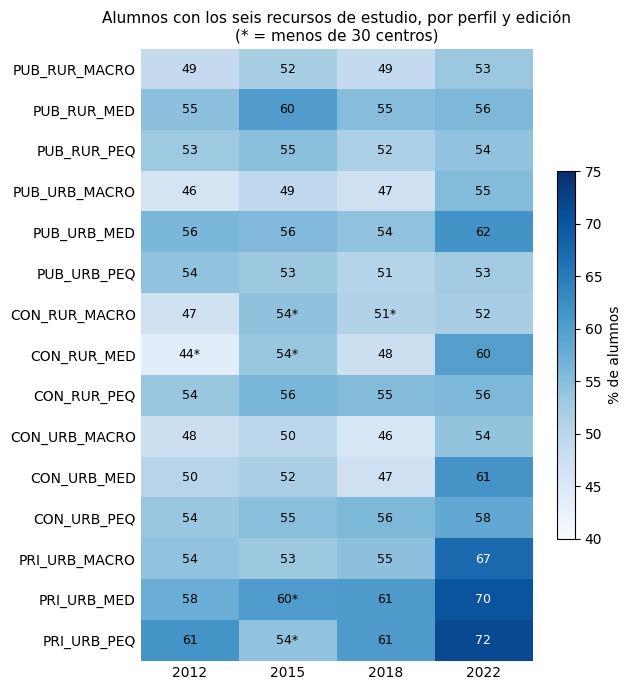

**Pendiente común por edición (error típico)**; los tramos, en puntos frente a «faltan dos o más»

year,2012,2015,2018,2022
termino,,,,
compromiso,10.72 (0.51),9.91 (0.44),11.58 (0.49),12.17 (0.45)
recursos: falta uno,8.71 (1.4),11.83 (1.34),10.46 (1.35),11.83 (1.18)
recursos: los seis,12.78 (1.37),13.55 (1.52),11.85 (1.48),14.98 (1.24)


**PRI_URB_MACRO**: diferencia de cada tramo con «faltan dos o más», por edición

year,2012,2015,2018,2022
termino,,,,
recursos_falta_uno:PRI_URB_MACRO,4.23 (9.3),15.52 (8.35),17.6 (8.35),29.72 (7.64)
recursos_los_seis:PRI_URB_MACRO,5.61 (8.73),17.06 (7.53),8.94 (9.22),45.94 (8.13)


,pendiente_2012,pendiente_2022,cambio,error_cambio,p_cambio,p_igualdad_perfiles_2022,p_igualdad_cambio,PRI_URB_MACRO_2012,PRI_URB_MACRO_2022,cambio_PRI_URB_MACRO,error_PRI_URB_MACRO,p_PRI_URB_MACRO,PRI_URB_MACRO_poco_representativo
variable,,,,,,,,,,,,,
Indice_Compromiso_Competencia,10.723,12.168,1.445,0.679,0.033,0.617,0.831,16.923,15.377,-1.546,3.696,0.676,False
recursos_falta_uno,8.705,11.834,3.129,1.832,0.088,0.541,0.484,4.228,29.716,25.489,12.034,0.034,False
recursos_los_seis,12.782,14.985,2.203,1.849,0.234,0.013,0.023,5.613,45.936,40.323,11.930,0.001,False


In [4]:
# Recursos de estudio en su escala original (0 a 6) y dos indicadores de tramo
escala_recursos = parametros[(parametros['variable'] == 'recursos_estudio') & (parametros['edicion'] == 'todas')].iloc[0]
recursos_original = (matriz['recursos_estudio'] * escala_recursos['desviacion_tipica'] + escala_recursos['media']).round(1)
matriz_tramos = matriz.assign(recursos_falta_uno=((recursos_original >= 4.5) & (recursos_original < 6)).astype(float),
                              recursos_los_seis=(recursos_original >= 6).astype(float),
                              tramo=np.select([recursos_original >= 6, recursos_original >= 4.5], ['los seis', 'falta uno'], 'faltan dos o más'))

# % ponderado de alumnos con los seis recursos, por perfil y edición
con_los_seis = (100 * agregar_media_ponderada(matriz_tramos, ['recursos_los_seis'], claves=['perfil', 'year'], peso_col='SENWT')
                .pivot(index='perfil', columns='year', values='recursos_los_seis')).loc[ORDEN_PERFILES]
print('% de alumnos con los seis recursos, todos los perfiles:',
      matriz_tramos.groupby('year').apply(lambda grupo: 100 * media_ponderada(grupo['recursos_los_seis'], grupo['SENWT']), include_groups=False).round(1).to_dict())
alumnos_tramo = matriz_tramos[matriz_tramos['perfil'] == PERFIL_REVISADO].groupby(['year', 'tramo']).size().unstack('tramo')
print(f'\nAlumnos de {PERFIL_REVISADO} por tramo:')
print(alumnos_tramo)

# Figura: mapa de calor del % con los seis recursos
fig, eje = plt.subplots(figsize=(6.5, 7))
imagen = eje.imshow(con_los_seis.to_numpy(), cmap='Blues', vmin=40, vmax=75, aspect='auto')
for fila in range(con_los_seis.shape[0]):
    for columna in range(con_los_seis.shape[1]):
        valor = con_los_seis.iloc[fila, columna]
        marca = '*' if poco_representativo[(con_los_seis.index[fila], con_los_seis.columns[columna])] else ''
        eje.text(columna, fila, f'{valor:.0f}{marca}', ha='center', va='center', fontsize=9, color='white' if valor > 62 else 'black')
eje.set_xticks(range(len(EDICIONES)), EDICIONES)
eje.set_yticks(range(len(ORDEN_PERFILES)), ORDEN_PERFILES)
eje.tick_params(length=0)
for borde in eje.spines.values():
    borde.set_visible(False)
fig.colorbar(imagen, ax=eje, shrink=0.6, label='% de alumnos')
eje.set_title('Alumnos con los seis recursos de estudio, por perfil y edición\n(* = menos de 30 centros)', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/03_robustez_techo_recursos.png', dpi=300, bbox_inches='tight')
plt.show()

# El modelo con los tramos en lugar de la escala continua (referencia: «faltan dos o más»)
de_interes_tramos = ['Indice_Compromiso_Competencia', 'recursos_falta_uno', 'recursos_los_seis']
resumen, comun_tramos, perfil_tramos = estimar_especificacion('recursos por tramos', matriz_tramos, poco_representativo, de_interes=de_interes_tramos)
resumenes.append(resumen)
display(Markdown('**Pendiente común por edición (error típico)**; los tramos, en puntos frente a «faltan dos o más»'))
display(pendientes_comunes(comun_tramos, de_interes_tramos))
display(Markdown(f'**{PERFIL_REVISADO}**: diferencia de cada tramo con «faltan dos o más», por edición'))
display(coeficientes_con_error(perfil_tramos, [f'{variable}:{PERFIL_REVISADO}' for variable in de_interes_tramos[1:]], decimales=2))
display(resumen.drop(columns=['especificacion', 'alumnos']).round(3).set_index('variable'))

**Qué se ve.**

* **Entre el 51,3 % y el 57,3 % de los alumnos tienen los seis recursos.** El techo crece en 2022, sobre todo en los privados urbanos: el grande pasa del 54 % en 2012 al 67 % en 2022 (gráfico).
* **Aun así, el privado urbano grande no se queda sin alumnos por debajo del techo.** Le quedan 206 alumnos con dos o más recursos de menos en 2012 y 251 en 2022.
* **Con tramos, la pendiente común sigue sin cambiar.**
  * «Falta uno» se asocia a 8,71 puntos más que «faltan dos o más» en 2012 y a 11,83 en 2022.
  * «Los seis», a 12,78 y 14,98 puntos.
  * Ninguno de los dos cambios se distingue de cero (p = 0,088 y 0,234).
  * Tener los seis añade poco sobre tener todos menos uno: la relación es creciente pero se aplana cerca del techo.
* **En el privado urbano grande, el salto se ve igual con tramos.**
  * En 2012, «los seis» se asocia a 5,61 puntos más que «faltan dos o más»; en 2022, a 45,94 (+40,32, p = 0,001).
  * «Falta uno» pasa de 4,23 a 29,72.
  * El cambio de «los seis» es distinto entre perfiles (p = 0,023).
* **El salto no es un artefacto de la escala lineal** ni de que haya pocos alumnos fuera del techo. En 2022, los alumnos de esos centros sin todos los recursos sacan mucha menos nota que sus compañeros, con lo demás igual.

## 4. Qué países hay detrás del privado urbano grande

Con el efecto fijo de país, la pendiente de un perfil compara alumnos del mismo país, pero el perfil puede estar formado por pocos países. Primero, sus alumnos y centros por país y edición. Después, el modelo completo sin cada uno de los países que tienen privados urbanos grandes en 2012 y en 2022: si el salto de la pendiente de los recursos se debe a un solo país, desaparece al quitarlo. Los perfiles poco representativos se recalculan sin ese país.

In [5]:
# Composición del privado urbano grande por país
revisado = matriz[matriz['perfil'] == PERFIL_REVISADO]
composicion = revisado.groupby(['CNT', 'year']).agg(alumnos=('CNTSTUID', 'size'), centros=('centro', 'nunique')).unstack('year').fillna(0).astype(int)
display(Markdown(f'**{PERFIL_REVISADO}**: alumnos y centros por país y edición'))
display(composicion)
paises_revisado = sorted(set(revisado.loc[revisado['year'] == INICIO, 'CNT']) & set(revisado.loc[revisado['year'] == FINAL, 'CNT']))
print('Países con el perfil en', INICIO, 'y', FINAL, ':', paises_revisado)

# El modelo sin cada país que tiene el perfil en 2012 y 2022
filas_paises = []
for pais in paises_revisado:
    resumen, _, _ = estimar_especificacion(f'sin {pais}', matriz[matriz['CNT'] != pais], perfiles_poco_representativos(tabla[tabla['CNT'] != pais]))
    resumenes.append(resumen)
    filas_paises.append(resumen)
columnas = ['especificacion', 'variable', f'{PERFIL_REVISADO}_{INICIO}', f'{PERFIL_REVISADO}_{FINAL}', f'cambio_{PERFIL_REVISADO}', f'error_{PERFIL_REVISADO}',
            f'p_{PERFIL_REVISADO}', f'{PERFIL_REVISADO}_poco_representativo', f'p_igualdad_perfiles_{FINAL}', 'p_igualdad_cambio']
display(pd.concat([resumenes[0]] + filas_paises).query('variable == "recursos_estudio"')[columnas].round(3).set_index('especificacion'))

**PRI_URB_MACRO**: alumnos y centros por país y edición

alumnos                   centros               
year    2012  2015  2018  2022    2012 2015 2018 2022
CNT                                                  
AUS      782  1147  1023  1495      63   65   63   80
DNK        0     0    10     0       0    0    1    0
ESP      375   225   637   671      18    6   27   21
GBR       76   102   115   266       4    4    4    9
GRC       22     0     0     0       1    0    0    0
KOR      476   469   190   137      21   14    5    4

Países con el perfil en 2012 y 2022 : ['AUS', 'ESP', 'GBR', 'KOR']


,variable,PRI_URB_MACRO_2012,PRI_URB_MACRO_2022,cambio_PRI_URB_MACRO,error_PRI_URB_MACRO,p_PRI_URB_MACRO,PRI_URB_MACRO_poco_representativo,p_igualdad_perfiles_2022,p_igualdad_cambio
especificacion,,,,,,,,,
modelo de partida,recursos_estudio,3.390,17.645,14.256,4.471,0.001,False,0.003,0.032
sin AUS,recursos_estudio,5.396,12.163,6.767,6.747,0.316,False,0.213,0.249
sin ESP,recursos_estudio,4.073,18.681,14.609,4.871,0.003,False,0.002,0.013
sin GBR,recursos_estudio,3.448,20.474,17.026,4.422,0.000,False,0.000,0.001
sin KOR,recursos_estudio,1.355,16.635,15.280,4.893,0.002,False,0.024,0.042


**Qué se ve.**

* **El privado urbano grande es, sobre todo, Australia.** Australia aporta 63 centros en 2012 y 80 en 2022, más que los demás países juntos. Corea pasa de 21 centros a 4, así que la composición del perfil también cambia entre ediciones.
* **Sin Australia, el resultado desaparece.**
  * La pendiente de los recursos del perfil pasa de 5,40 a 12,16, un cambio de 6,77 puntos (p = 0,316).
  * En 2022 ya no se rechaza que los perfiles tengan la misma pendiente (p = 0,213), ni que el cambio sea igual en todos (p = 0,249).
* **Sin cualquiera de los otros tres países, el resultado se mantiene**: el cambio es de 14,61 sin España, 17,03 sin Reino Unido y 15,28 sin Corea, con p de 0,003 o menos.
* **En el panel común, lo que el modelo detecta es un cambio en los privados urbanos grandes australianos, más que un rasgo del perfil en general.** Con efecto fijo de país, es una diferencia dentro de Australia: en 2022 los recursos de estudio se asocian a más nota en sus privados grandes que en sus demás centros. La sección 7 repite la comprobación con todos los países y en el panel ampliado, donde la conclusión cambia.
* **El compromiso es menos estable de lo que parecía.** Su subida va de 1,28 a 1,97 puntos según el país que se quite, con p entre 0,004 (sin Corea) y 0,068 (sin Reino Unido).

## 5. Controles del centro

* **`ESCS` medio del centro en lugar de la composición social.** La composición social se construye con la ocupación y los estudios de los padres; el `ESCS` de la OCDE añade las posesiones del hogar. Miden casi lo mismo, pero el `ESCS` incluye bienes del hogar parecidos a los recursos de estudio.
* **Con la escasez del centro.** La escasez de material y de personal según el director (`01_EDA_recursos_centro`), además de la dotación. Se tipifica dentro de cada edición y en 2022 falta en muchos centros (con su indicador de «sin dato»).

In [6]:
# Dos alternativas a los controles del centro
especificaciones = {'ESCS del centro en lugar de composición social': [variable if variable != 'composicion_social_centro' else 'escs_centro' for variable in CONTROLES],
                    'con la escasez del centro': CONTROLES + ['escasez_centro']}
for nombre, controles in especificaciones.items():
    resumen, _, _ = estimar_especificacion(nombre, matriz, poco_representativo, controles=controles)
    resumenes.append(resumen)
    display(Markdown(f'**{nombre}**'))
    display(resumen.drop(columns=['especificacion', 'alumnos']).round(3).set_index('variable').T)

**ESCS del centro en lugar de composición social**

variable,Indice_Compromiso_Competencia,recursos_estudio
pendiente_2012,10.594,4.459
pendiente_2022,11.85,5.193
cambio,1.255,0.733
error_cambio,0.673,0.701
p_cambio,0.062,0.295
p_igualdad_perfiles_2022,0.449,0.001
p_igualdad_cambio,0.742,0.04
PRI_URB_MACRO_2012,17.024,2.258
PRI_URB_MACRO_2022,14.875,16.961
cambio_PRI_URB_MACRO,-2.149,14.703


**con la escasez del centro**

variable,Indice_Compromiso_Competencia,recursos_estudio
pendiente_2012,10.641,5.434
pendiente_2022,12.111,5.897
cambio,1.47,0.463
error_cambio,0.678,0.702
p_cambio,0.03,0.51
p_igualdad_perfiles_2022,0.708,0.004
p_igualdad_cambio,0.846,0.031
PRI_URB_MACRO_2012,17.234,3.247
PRI_URB_MACRO_2022,15.215,17.585
cambio_PRI_URB_MACRO,-2.019,14.338


**Qué se ve.**

* **Con el `ESCS` medio del centro, las pendientes de los recursos bajan** (4,46 en 2012 y 5,19 en 2022), porque el `ESCS` ya incluye posesiones del hogar.
  * El cambio de los recursos sigue sin distinguirse de cero (+0,73, p = 0,295).
  * El privado urbano grande se mantiene (+14,70, p = 0,001).
  * El cambio del compromiso baja a 1,26 (p = 0,062).
* **Con la escasez del centro, todo queda casi igual que en el modelo de partida**: compromiso +1,47 (p = 0,030), recursos +0,46 (p = 0,510) y privado urbano grande +14,34 (p = 0,001).

## 6. Panel ampliado de 25 países

El panel común tiene 12 países porque el índice de compromiso necesita la pregunta de deberes en 2018. Sin 2018 entran 25 países (`src/tabla_alumno.py`, `PANELES`), con el índice de compromiso calculado con esos 25 (`01_EDA_indice_de_compromiso_competencia`, sección 5.7.6). La tabla se construye y se prepara igual que en `02_preparacion_modelo` (umbral de centros, tipificación con sus propios alumnos), sin guardarla. Las pendientes están en desviaciones típicas de este panel, así que su nivel no es exactamente comparable con el del panel común; su cambio y sus contrastes sí.

In [7]:
# Tabla del panel de 25 países, con su propio universo y su propia escala
tabla_ampliada = marcar_universo(tabla_por_alumno(RUTA_RAW_BASE, RUTA_INTERMEDIOS, panel='ampliado'))
matriz_ampliada = matriz_regresion(tabla_ampliada, parametros_escala(tabla_ampliada))
poco_ampliado = perfiles_poco_representativos(tabla_ampliada)
print(f"{tabla_ampliada['CNT'].nunique()} países; alumnos en el modelo por edición:", matriz_ampliada.groupby('year').size().to_dict())
print('Perfiles excluidos:', sorted(tabla_ampliada.loc[tabla_ampliada['perfil_excluido'], 'perfil'].unique()))
print('Perfiles-edición poco representativos (de los que entran):',
      [indice for indice, valor in poco_ampliado.items() if valor and indice[0] in set(matriz_ampliada['perfil'])])
print(f'Alumnos de {PERFIL_REVISADO} por país y edición:')
print(matriz_ampliada[matriz_ampliada['perfil'] == PERFIL_REVISADO].groupby(['CNT', 'year']).size().unstack('year').fillna(0).astype(int))

resumen, comun_ampliado, perfil_ampliado = estimar_especificacion('panel ampliado (25 países)', matriz_ampliada, poco_ampliado)
resumenes.append(resumen)
display(Markdown('**Pendiente común por edición (error típico)**'))
display(pendientes_comunes(comun_ampliado, DE_INTERES))
display(resumen.drop(columns=['especificacion', 'alumnos']).round(3).set_index('variable').T)

25 países; alumnos en el modelo por edición: {2012: 136528, 2015: 133661, 2022: 151555}
Perfiles excluidos: ['PRI_RUR_MACRO', 'PRI_RUR_MED']


Perfiles-edición poco representativos (de los que entran): [('CON_RUR_MACRO', 2015), ('PRI_RUR_PEQ', 2015)]
Alumnos de PRI_URB_MACRO por país y edición:
year  2012  2015  2022
CNT                   
AUS    782  1147  1495
CHE      0     0    30
CHL    664   843   778
CZE      0    36     0
ESP    375   225   671
EST      0    36     0
FRA      0   145   201
GBR     76   102   266
GRC     22     0     0
JPN    586   929   883
KOR    476   469   137
MEX    226   111     1
NLD      0     0    18
PRT    127   113   288
USA     69     0    26


**Pendiente común por edición (error típico)**

year,2012,2015,2022
termino,,,
compromiso,9.06 (0.36),8.82 (0.3),11.44 (0.29)
recursos de estudio,4.51 (0.37),5.13 (0.43),6.1 (0.34)


variable,Indice_Compromiso_Competencia,recursos_estudio
pendiente_2012,9.056,4.505
pendiente_2022,11.438,6.102
cambio,2.383,1.597
error_cambio,0.458,0.505
p_cambio,0.0,0.002
p_igualdad_perfiles_2022,0.034,0.0
p_igualdad_cambio,0.15,0.019
PRI_URB_MACRO_2012,10.433,7.787
PRI_URB_MACRO_2022,8.325,17.024
cambio_PRI_URB_MACRO,-2.108,9.236


**Qué se ve.**

* **El panel ampliado tiene 25 países** y entre 133.661 y 151.555 alumnos por edición, casi el doble que el común.
  * Quedan excluidos dos perfiles (`PRI_RUR_MACRO`, `PRI_RUR_MED`).
  * Solo dos perfiles-edición son poco representativos.
  * El privado urbano grande suma Japón, Chile, Portugal y Francia.
* **Las dos pendientes suben de 2012 a 2022, y con más claridad que en el panel común.**
  * Compromiso: de 9,06 a 11,44 (+2,38, p < 0,001).
  * Recursos de estudio: de 4,51 a 6,10 (+1,60, p = 0,002). En el panel común no había cambio.
* **Los recursos vuelven a diferir entre perfiles en 2022** (p < 0,001), y también su cambio (p = 0,019). El privado urbano grande sube 9,24 puntos (p = 0,012), menos que en el panel común.
* **En el compromiso, los perfiles difieren algo en 2022** (p = 0,034), pero su cambio no se distingue entre perfiles (p = 0,150).
* **Las diferencias con el panel común pueden venir de los países o del índice.** El índice de este panel se calcula con sus propios terciles de deberes y sin 2018, así que no se sabe cuánto de la diferencia es de los países y cuánto de la medida.

## 7. Quitar cada país, uno a uno

La sección 4 quita solo los países del privado urbano grande, elegidos después de ver el resultado. Aquí se hace lo mismo con todos los países y en los dos paneles, para ver si alguna conclusión sobre los perfiles depende de un solo país, en cualquier perfil.

* Primero, cuánto pesa en cada perfil-edición el país con más centros: si un perfil está dominado por un país, su pendiente es sobre todo la de ese país.
* Después, el modelo completo sin cada país, con cuatro contrastes: si las pendientes de los perfiles son iguales en 2022 y si su cambio desde 2012 es igual en todos, para el compromiso y para los recursos de estudio. Se señalan los países cuya ausencia cambia la conclusión al 5 % respecto al panel completo.
* Por último, el cambio de la pendiente común del compromiso de 2012 a 2022, el hallazgo principal sobre el compromiso.

**Panel común: país con más centros en cada perfil-edición (% de los centros del perfil)**

year,2012,2015,2018,2022
perfil,,,,
PUB_RUR_MACRO,GBR 59%,GBR 51%,ITA 35%,GBR 41%
PUB_RUR_MED,ESP 24%,GBR 18%,ESP 32%,ESP 28%
PUB_RUR_PEQ,ITA 24%,SVK 17%,ESP 18%,ESP 19%
PUB_URB_MACRO,ITA 34%,AUS 30%,AUS 30%,AUS 30%
PUB_URB_MED,ITA 28%,AUS 14%,ESP 24%,ESP 19%
PUB_URB_PEQ,ITA 27%,GRC 22%,GRC 23%,GRC 25%
CON_RUR_MACRO,GBR 50%,AUS 54%,GBR 50%,GBR 56%
CON_RUR_MED,ESP 57%,AUS 64%,ESP 44%,ESP 50%
CON_RUR_PEQ,ESP 39%,DNK 28%,ESP 29%,ESP 33%


Perfiles-edición con más de la mitad de sus centros en un país: 12 de 60


**Panel ampliado: país con más centros en cada perfil-edición (% de los centros del perfil)**

year,2012,2015,2022
perfil,,,
PUB_RUR_MACRO,GBR 34%,GBR 26%,GBR 21%
PUB_RUR_MED,ESP 14%,GBR 9%,ESP 17%
PUB_RUR_PEQ,MEX 28%,CZE 9%,CZE 12%
PUB_URB_MACRO,MEX 22%,AUS 15%,AUS 15%
PUB_URB_MED,ITA 17%,CZE 10%,ESP 10%
PUB_URB_PEQ,ITA 17%,GRC 14%,GRC 17%
CON_RUR_MACRO,GBR 35%,AUS 33%,GBR 39%
CON_RUR_MED,ESP 36%,AUS 41%,ESP 38%
CON_RUR_PEQ,ESP 31%,DNK 18%,ESP 27%


Perfiles-edición con más de la mitad de sus centros en un país: 1 de 48


... (5 outputs left out)

cambio        error_cambio        p_cambio       
panel        ampliado  común     ampliado  común ampliado  común
pais_quitado                                                    
AUS             2.367  1.348        0.473  0.722      0.0  0.062
CHE             2.230    NaN        0.468    NaN      0.0    NaN
CHL             2.370    NaN        0.469    NaN      0.0    NaN
CZE             2.296    NaN        0.465    NaN      0.0    NaN
DEU             2.349    NaN        0.469    NaN      0.0    NaN
DNK             2.489  1.593        0.477  0.717      0.0  0.026
ESP             2.416  1.535        0.480  0.745      0.0  0.039
EST             2.552    NaN        0.466    NaN      0.0    NaN
FIN             2.224    NaN        0.472    NaN      0.0    NaN
FRA             2.292    NaN        0.471    NaN      0.0    NaN
GBR             2.317  1.276        0.462  0.699      0.0  0.068
GRC             2.398  1.424        0.467  0.719      0.0  0.048
HUN             2.364  1.291        0.465  0.707      0.0  0.068
ISL             2.494  1.565        0.464  0.676      0.0  0.021
ITA             2.290  1.174        0.473  0.716      0.0  0.101
JPN             2.545    NaN        0.464    NaN      0.0    NaN
KOR             2.663  1.970        0.460  0.677      0.0  0.004
MEX             2.480    NaN        0.471    NaN      0.0    NaN
NLD             2.281    NaN        0.457    NaN      0.0    NaN
POL             2.738  2.189        0.473  0.717      0.0  0.002
PRT             2.318    NaN        0.472    NaN      0.0    NaN
SVK             2.267  1.046        0.464  0.711      0.0  0.141
SVN             2.405  1.324        0.468  0.704      0.0  0.060
TUR             2.272    NaN        0.464    NaN      0.0    NaN
USA             2.144    NaN        0.465    NaN      0.0    NaN
ninguno         2.383  1.481        0.458  0.678      0.0  0.029

Panel común: cambio entre 1.05 y 2.19, error típico entre 0.68 y 0.75, p entre 0.002 y 0.141; sin qué país p > 0,05: ['AUS', 'GBR', 'HUN', 'ITA', 'SVK', 'SVN']
Panel ampliado: cambio entre 2.14 y 2.74, error típico entre 0.46 y 0.48, p entre 0.000 y 0.000; sin qué país p > 0,05: []


**Panel ampliado: pendiente de los recursos de estudio por perfil (error típico), con todos los países y sin AUS**; `*` = poco representativo en 2022

con todos                             sin AUS                          poco_representativo
year                 2012        2015        2022        2012        2015         2022                    
PUB_RUR_MACRO   6.0 (1.6)   5.6 (1.5)   5.8 (1.8)   6.1 (1.7)   5.3 (1.5)    5.6 (1.8)                    
PUB_RUR_MED     5.7 (1.3)   5.5 (1.2)   5.9 (1.2)   5.9 (1.3)   5.4 (1.2)    5.9 (1.2)                    
PUB_RUR_PEQ     2.2 (0.8)   3.5 (0.9)   3.6 (1.0)   2.0 (0.8)   3.5 (0.9)    3.6 (1.0)                    
PUB_URB_MACRO   5.4 (0.8)   5.6 (0.7)   5.8 (0.7)   5.4 (0.8)   5.5 (0.8)    5.4 (0.7)                    
PUB_URB_MED     4.5 (0.8)   4.9 (0.8)   7.4 (0.7)   4.6 (0.8)   4.9 (0.8)    7.3 (0.7)                    
PUB_URB_PEQ     4.0 (1.2)   5.8 (1.0)   4.4 (0.9)   4.0 (1.2)   5.8 (1.0)    4.3 (0.9)                    
CON_RUR_MACRO  13.3 (5.8)   7.4 (4.3)   9.1 (4.4)  12.1 (5.9)   7.4 (4.9)    9.0 (4.5)                    
CON_RUR_MED    -7.7 (4.8)  12.2 (4.5)  -0.0 (7.6)  -8.2 (4.9)  14.7 (5.0)   -0.3 (7.9)                    
CON_RUR_PEQ     5.2 (3.2)   6.0 (3.6)  15.9 (3.9)   4.2 (3.1)   5.8 (3.6)   15.8 (3.9)                    
CON_URB_MACRO   6.3 (2.1)   4.5 (1.7)   9.8 (1.7)   7.2 (2.3)   5.2 (1.8)   10.4 (1.9)                    
CON_URB_MED     2.6 (2.2)   7.0 (2.2)   6.6 (1.9)   2.6 (2.4)   6.9 (2.4)    6.5 (2.0)                    
CON_URB_PEQ     5.4 (3.3)   5.7 (2.5)   3.2 (2.2)   5.1 (3.4)   5.8 (2.5)    2.8 (2.3)                    
PRI_URB_MACRO   7.8 (2.9)   7.1 (2.3)  17.0 (2.2)   8.3 (3.1)   7.3 (2.6)   14.9 (2.6)                    
PRI_URB_MED     9.3 (4.0)   6.5 (2.7)  14.4 (3.8)   8.8 (4.2)   6.8 (2.8)   15.0 (4.0)                    
PRI_URB_PEQ    10.2 (3.1)   4.1 (3.0)  -1.7 (2.6)  10.0 (3.2)   4.3 (3.0)   -2.0 (2.6)                    
PRI_RUR_PEQ    -6.5 (9.5)   3.1 (6.7)  -9.7 (5.6)  -5.1 (9.7)   3.1 (6.7)  -10.8 (5.9)

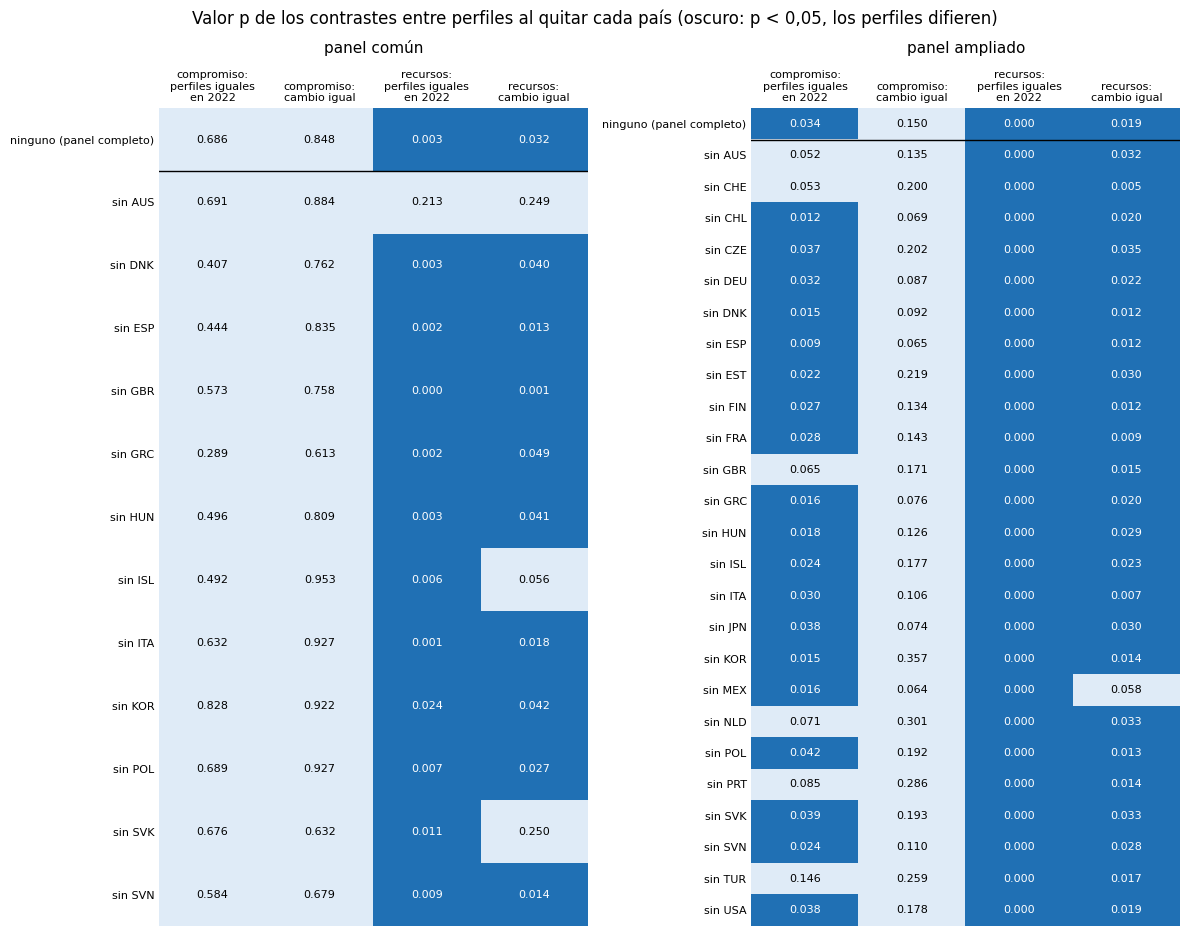

In [8]:
def pais_dominante(matriz_panel):
    """País con más centros de cada perfil-edición y su porcentaje de los centros del perfil."""
    centros = matriz_panel.groupby(['perfil', 'year', 'CNT'])['centro'].nunique()
    filas = []
    for (perfil, edicion), grupo in centros.groupby(level=['perfil', 'year']):
        grupo = grupo.droplevel(['perfil', 'year'])
        filas.append({'perfil': perfil, 'year': edicion, 'pais': grupo.idxmax(), 'porcentaje': 100 * grupo.max() / grupo.sum()})
    return pd.DataFrame(filas)


# Primero, qué país domina cada perfil-edición en cada panel
paneles = {'común': (tabla, matriz, 'modelo de partida'), 'ampliado': (tabla_ampliada, matriz_ampliada, 'panel ampliado (25 países)')}
for panel, (_, matriz_panel, _) in paneles.items():
    dominante = pais_dominante(matriz_panel)
    texto = dominante['pais'] + ' ' + dominante['porcentaje'].round(0).astype(int).astype(str) + '%'
    display(Markdown(f'**Panel {panel}: país con más centros en cada perfil-edición (% de los centros del perfil)**'))
    display(dominante.assign(texto=texto).pivot(index='perfil', columns='year', values='texto').reindex([perfil for perfil in ORDEN_PERFILES if perfil in set(dominante['perfil'])]))
    print(f'Perfiles-edición con más de la mitad de sus centros en un país: {(dominante["porcentaje"] > 50).sum()} de {len(dominante)}')

# El modelo sin cada país, en los dos paneles
resumenes_sin_pais, perfil_sin_pais = [], {}
for panel, (tabla_panel, matriz_panel, referencia) in paneles.items():
    for pais in sorted(matriz_panel['CNT'].unique()):
        resumen, _, perfil_sin_pais[(panel, pais)] = estimar_especificacion(f'panel {panel} sin {pais}', matriz_panel[matriz_panel['CNT'] != pais],
                                                                             perfiles_poco_representativos(tabla_panel[tabla_panel['CNT'] != pais]))
        resumenes_sin_pais.append(resumen.assign(panel=panel, pais_quitado=pais))
sin_pais = pd.concat(resumenes_sin_pais, ignore_index=True)
referencias = pd.concat(resumenes, ignore_index=True)
referencias = pd.concat([referencias[referencias['especificacion'] == referencia].assign(panel=panel, pais_quitado='ninguno')
                         for panel, (_, _, referencia) in paneles.items()], ignore_index=True)

# Valor p de los contrastes entre perfiles con todos los países y sin cada uno
CONTRASTES = [(variable, columna) for variable in DE_INTERES for columna in (f'p_igualdad_perfiles_{FINAL}', 'p_igualdad_cambio')]
NOMBRES_CONTRASTE = {f'p_igualdad_perfiles_{FINAL}': f'perfiles iguales en {FINAL}', 'p_igualdad_cambio': 'cambio igual'}
ETIQUETAS_CONTRASTE = [f'{NOMBRES[variable].split()[0]}:\n' + NOMBRES_CONTRASTE[columna].replace(' en ', '\nen ') for variable, columna in CONTRASTES]
contrastes = pd.concat([referencias, sin_pais]).pivot(index=['panel', 'pais_quitado'], columns='variable',
                                                       values=[f'p_igualdad_perfiles_{FINAL}', 'p_igualdad_cambio']).astype(float)
display(Markdown('**Valor p de cada contraste, sin cada país**'))
display(contrastes.round(3))

# Países cuya ausencia hace cruzar el 5 % a algún contraste
filas = []
for panel in paneles:
    de_panel = contrastes.loc[panel]
    for variable, columna in CONTRASTES:
        significativo = de_panel[(columna, variable)] < 0.05
        for pais in de_panel.index[significativo != significativo['ninguno']]:
            filas.append({'panel': panel, 'pais_quitado': pais, 'variable': NOMBRES[variable], 'contraste': NOMBRES_CONTRASTE[columna],
                          'p_con_todos': de_panel.loc['ninguno', (columna, variable)], 'p_sin_el_pais': de_panel.loc[pais, (columna, variable)]})
cambian = pd.DataFrame(filas)
display(Markdown('**Países cuya ausencia cambia la conclusión de un contraste al 5 %**'))
display(cambian.round(3) if len(cambian) else 'ninguno')

# Cambio de la pendiente común del compromiso de 2012 a 2022, con todos los países y sin cada uno
cambio_compromiso = pd.concat([referencias, sin_pais])
cambio_compromiso = cambio_compromiso[cambio_compromiso['variable'] == 'Indice_Compromiso_Competencia'].set_index(['panel', 'pais_quitado'])[['cambio', 'error_cambio', 'p_cambio']]
display(Markdown(f'**Cambio de la pendiente común del compromiso de {INICIO} a {FINAL} (puntos por desviación típica), sin cada país**'))
display(cambio_compromiso.unstack('panel').round(3))
for panel in paneles:
    de_panel = cambio_compromiso.loc[panel].drop('ninguno')
    print(f'Panel {panel}: cambio entre {de_panel["cambio"].min():.2f} y {de_panel["cambio"].max():.2f}, '
          f'error típico entre {de_panel["error_cambio"].min():.2f} y {de_panel["error_cambio"].max():.2f}, '
          f'p entre {de_panel["p_cambio"].min():.3f} y {de_panel["p_cambio"].max():.3f}; sin qué país p > 0,05:', sorted(de_panel.index[de_panel['p_cambio'] > 0.05]))

# Qué perfiles hacen distintas las pendientes de los recursos en 2022 en el panel ampliado, con y sin Australia
terminos = sorted(termino for termino in perfil_ampliado.index.get_level_values('termino').unique() if termino.startswith('recursos_estudio:'))
pendientes_ampliado = pd.concat({'con todos': con_error_perfil(perfil_ampliado, terminos), 'sin AUS': con_error_perfil(perfil_sin_pais[('ampliado', 'AUS')], terminos)}, axis=1)
marca = pd.Series({perfil: '*' if poco_ampliado[(perfil, FINAL)] else '' for perfil in pendientes_ampliado.index})
display(Markdown(f'**Panel ampliado: pendiente de los recursos de estudio por perfil (error típico), con todos los países y sin AUS**; `*` = poco representativo en {FINAL}'))
display(pendientes_ampliado.assign(poco_representativo=marca).reindex([perfil for perfil in ORDEN_PERFILES + ['PRI_RUR_PEQ'] if perfil in pendientes_ampliado.index]))

# Figura: mapa de los valores p sin cada país
fig, ejes = plt.subplots(1, 2, figsize=(12, 9.5), gridspec_kw={'height_ratios': [1], 'width_ratios': [1, 1]})
for eje, panel in zip(ejes, paneles):
    de_panel = contrastes.loc[panel]
    orden_paises = ['ninguno'] + [pais for pais in de_panel.index if pais != 'ninguno']
    valores = np.array([[de_panel.loc[pais, (columna, variable)] for variable, columna in CONTRASTES] for pais in orden_paises], dtype=float)
    eje.imshow(valores < 0.05, cmap=plt.matplotlib.colors.ListedColormap([plt.cm.Blues(0.12), plt.cm.Blues(0.75)]), aspect='auto', vmin=0, vmax=1)
    for fila in range(valores.shape[0]):
        for columna in range(valores.shape[1]):
            eje.text(columna, fila, f'{valores[fila, columna]:.3f}', ha='center', va='center', fontsize=8,
                     color='white' if valores[fila, columna] < 0.05 else 'black')
    eje.set_xticks(range(len(CONTRASTES)), ETIQUETAS_CONTRASTE, fontsize=8)
    eje.set_yticks(range(len(orden_paises)), ['ninguno (panel completo)' if pais == 'ninguno' else f'sin {pais}' for pais in orden_paises], fontsize=8)
    eje.axhline(0.5, color='black', linewidth=1)
    eje.tick_params(length=0)
    eje.xaxis.tick_top()
    for borde in eje.spines.values():
        borde.set_visible(False)
    eje.set_title(f'panel {panel}', fontsize=11, pad=40)
fig.suptitle('Valor p de los contrastes entre perfiles al quitar cada país (oscuro: p < 0,05, los perfiles difieren)', fontsize=12)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/03_robustez_sin_cada_pais.png', dpi=300, bbox_inches='tight')
plt.show()

**Qué se ve.**

* **En el panel común, varios perfiles dependen mucho de un país.**
  * En 12 de los 60 perfiles-edición, más de la mitad de los centros son de un solo país.
  * El caso más claro es el privado urbano grande: Australia tiene entre el 59 % y el 73 % de sus centros.
  * En el panel ampliado eso pasa en 1 de 48, y Australia baja al 35-43 % del privado urbano grande.
* **Panel común: solo Australia cambia una conclusión de verdad.**
  * En el compromiso, ningún país cambia nada. Los perfiles siguen siendo iguales en 2022 (p entre 0,289 y 0,828) y en su cambio (p entre 0,613 y 0,953).
  * En los recursos de estudio, sin Australia desaparecen las dos diferencias entre perfiles (p = 0,213 y 0,249).
  * Sin Islandia o sin Eslovaquia el cambio deja de ser distinto entre perfiles (p = 0,056 y 0,250), pero las pendientes de 2022 siguen difiriendo (p = 0,006 y 0,011).
* **Panel ampliado: la diferencia de los recursos en 2022 no depende de ningún país.**
  * Las pendientes de los perfiles difieren con p < 0,001 se quite el país que se quite, también sin Australia.
  * El cambio desde 2012 difiere con p entre 0,005 y 0,058 (solo sin México pasa de 0,05).
* **Lo que separa a los perfiles en el panel ampliado son los privados urbanos.**
  * En 2022, el privado urbano grande (17,0 puntos por desviación típica; sin Australia, 14,9) y el mediano (14,4; sin Australia, 15,0) quedan muy por encima de los públicos (entre 3,6 y 7,4).
  * El privado urbano pequeño queda por debajo (−1,7).
  * El concertado rural pequeño también sube (15,9).
  * En 2012, el privado urbano grande estaba en 7,8 (sin Australia, 8,3).
* **La subida del compromiso en el panel común es poco precisa, pero no depende de un país.**
  * Con todos los países es de 1,48 puntos (p = 0,029). Sin cada país queda entre 1,05 y 2,19, siempre positiva, con un error típico de entre 0,68 y 0,75.
  * Como la significación es justa, perder un país basta para pasar de 0,05: ocurre sin Australia, Reino Unido, Hungría, Italia, Eslovaquia o Eslovenia (p hasta 0,141). La estimación apenas se mueve; lo que se pierde es precisión.
  * En el panel ampliado la subida es mayor (entre 2,14 y 2,74 sin cada país) y su p es menor de 0,001 se quite el país que se quite.
* **La diferencia en el compromiso es frágil.** En el panel ampliado, la de 2022 (p = 0,034) desaparece al quitar Australia, Suiza, Reino Unido, Países Bajos, Portugal o Turquía.
* **La respuesta sobre los recursos de estudio depende, por tanto, del panel.**
  * Con 12 países, la única diferencia entre perfiles es Australia.
  * Con 25, en 2022 los recursos se asocian a más nota en los privados urbanos grandes y medianos que en los públicos, sin depender de un país concreto.
  * El panel ampliado tiene su propio índice de compromiso y no tiene 2018, así que no se puede decir cuál de los dos es el bueno sin rehacer el análisis con una medida común a ambos (sección 8).

## 8. Asistencia y deberes por separado en el panel ampliado

Las secciones 6 y 7 dejan una pregunta abierta. El panel ampliado cambia dos cosas a la vez: los países y el índice de compromiso (sus terciles de deberes se calculan con los 25 países y no tiene 2018). No se sabe cuál de los dos cambios mueve los resultados. Aquí se separan:

* **Solo absentismo e impuntualidad, con las cuatro ediciones.** Las dos preguntas existen en los 25 países también en 2018, así que el panel ampliado recupera esa edición. La muestra son los alumnos con esas dos preguntas y los recursos de estudio, como la «muestra ampliada» de la sección 2 en el panel común.
* **Los tres componentes del índice**, con la muestra que tiene la pregunta de deberes (sin 2018). Es la sección 2 repetida en el panel ampliado: muestra qué componente lleva la subida del índice en este panel.

La tabla se construye con `tabla_por_alumno(..., panel='ampliado', ediciones=EDICIONES)`: los países y el índice son los del panel ampliado, y en 2018 el índice y el tercil de deberes quedan vacíos. Los perfiles excluidos y poco representativos se cuentan con todos los alumnos con perfil de esa tabla. Al final se compara el cambio de los recursos de estudio en las cinco especificaciones que separan países y medida: panel común o ampliado, con el índice, sus componentes o solo la asistencia.

25 países; perfiles excluidos: ['PRI_RUR_MACRO', 'PRI_RUR_MED']
Perfiles-edición poco representativos (de los que entran): [('CON_RUR_MACRO', 2015), ('PRI_RUR_PEQ', 2015)]
% de alumnos con perfil que tienen absentismo, impuntualidad y recursos de estudio, por edición: {2012: 97.3, 2015: 95.2, 2018: 80.8, 2022: 84.7}


**sin deberes, panel ampliado con 2018**: alumnos por edición {2012: 209459, 2015: 144314, 2018: 148299, 2022: 157643}; pendiente común por edición (error típico)

year,2012,2015,2018,2022
termino,,,,
absentismo,-16.31 (0.7),-15.16 (0.7),-17.74 (0.74),-14.51 (0.66)
impuntualidad,-11.95 (0.46),-10.58 (0.45),-10.64 (0.41),-11.67 (0.39)
recursos de estudio,4.8 (0.33),5.36 (0.43),5.42 (0.4),6.57 (0.33)


,pendiente_2012,pendiente_2022,cambio,error_cambio,p_cambio,p_igualdad_perfiles_2022,p_igualdad_cambio,PRI_URB_MACRO_2012,PRI_URB_MACRO_2022,cambio_PRI_URB_MACRO,error_PRI_URB_MACRO,p_PRI_URB_MACRO,PRI_URB_MACRO_poco_representativo
variable,,,,,,,,,,,,,
SKIPPING,-16.311,-14.512,1.799,0.960,0.061,0.388,0.010,-26.206,-8.330,17.876,5.952,0.003,False
TARDYSD,-11.950,-11.674,0.276,0.609,0.650,0.082,0.292,-12.172,-11.441,0.731,3.856,0.850,False
recursos_estudio,4.801,6.574,1.773,0.469,0.000,0.000,0.022,7.114,17.732,10.618,3.537,0.003,False


**componentes del índice, panel ampliado**: alumnos por edición {2012: 136528, 2015: 133661, 2022: 151555}; pendiente común por edición (error típico)

year,2012,2015,2022
termino,,,
absentismo,-15.88 (0.84),-14.76 (0.71),-14.13 (0.69)
deberes en el tercil central,-1.53 (0.65),-3.06 (0.59),5.73 (0.6)
impuntualidad,-11.41 (0.57),-10.6 (0.43),-11.49 (0.39)
recursos de estudio,4.42 (0.37),5.01 (0.43),6.12 (0.34)


,pendiente_2012,pendiente_2022,cambio,error_cambio,p_cambio,p_igualdad_perfiles_2022,p_igualdad_cambio,PRI_URB_MACRO_2012,PRI_URB_MACRO_2022,cambio_PRI_URB_MACRO,error_PRI_URB_MACRO,p_PRI_URB_MACRO,PRI_URB_MACRO_poco_representativo
variable,,,,,,,,,,,,,
deberes_en_u,-1.534,5.729,7.263,0.881,0.000,0.677,0.764,3.726,2.219,-1.508,4.871,0.757,False
SKIPPING,-15.879,-14.133,1.746,1.082,0.107,0.348,0.091,-23.018,-8.934,14.083,6.411,0.028,False
TARDYSD,-11.413,-11.491,-0.078,0.691,0.910,0.082,0.308,-10.381,-11.431,-1.050,3.997,0.793,False
recursos_estudio,4.416,6.119,1.704,0.503,0.001,0.000,0.018,7.850,17.270,9.420,3.653,0.010,False


**sin deberes, panel ampliado con 2018**: pendiente de los recursos de estudio por perfil y edición (error típico)

year,2012,2015,2018,2022,poco_representativo
PUB_RUR_MACRO,6.0 (1.5),5.7 (1.5),4.5 (2.0),6.1 (1.7),
PUB_RUR_MED,6.4 (1.3),4.8 (1.1),5.0 (1.3),6.9 (1.2),
PUB_RUR_PEQ,2.2 (0.7),3.8 (0.9),4.0 (1.0),3.9 (1.0),
PUB_URB_MACRO,5.6 (0.7),5.7 (0.7),5.8 (0.7),6.4 (0.7),
PUB_URB_MED,5.0 (0.7),4.9 (0.8),5.1 (0.8),7.9 (0.7),
PUB_URB_PEQ,4.6 (1.0),6.5 (1.0),5.6 (1.0),4.7 (0.9),
CON_RUR_MACRO,17.0 (5.0),7.1 (4.2),6.3 (4.0),10.2 (4.2),2015
CON_RUR_MED,-3.3 (4.9),11.9 (4.6),8.8 (4.7),1.7 (7.1),
CON_RUR_PEQ,3.3 (3.2),6.0 (3.0),6.6 (3.4),14.3 (3.9),
CON_URB_MACRO,6.3 (1.8),4.9 (1.6),6.3 (1.5),10.0 (1.7),


**Recursos de estudio: cambio de 2012 a 2022 según el panel y la medida del compromiso**

cambio  p_cambio  p_igualdad_perfiles_2022  p_igualdad_cambio  cambio_PRI_URB_MACRO  p_PRI_URB_MACRO
panel    compromiso medido con                                                                                                      
común    índice                  0.458     0.514                     0.003              0.032                14.256            0.001
         asistencia              0.848     0.187                     0.003              0.002                17.851            0.000
ampliado índice                  1.597     0.002                     0.000              0.019                 9.236            0.012
         asistencia              1.773     0.000                     0.000              0.022                10.618            0.003
         componentes             1.704     0.001                     0.000              0.018                 9.420            0.010

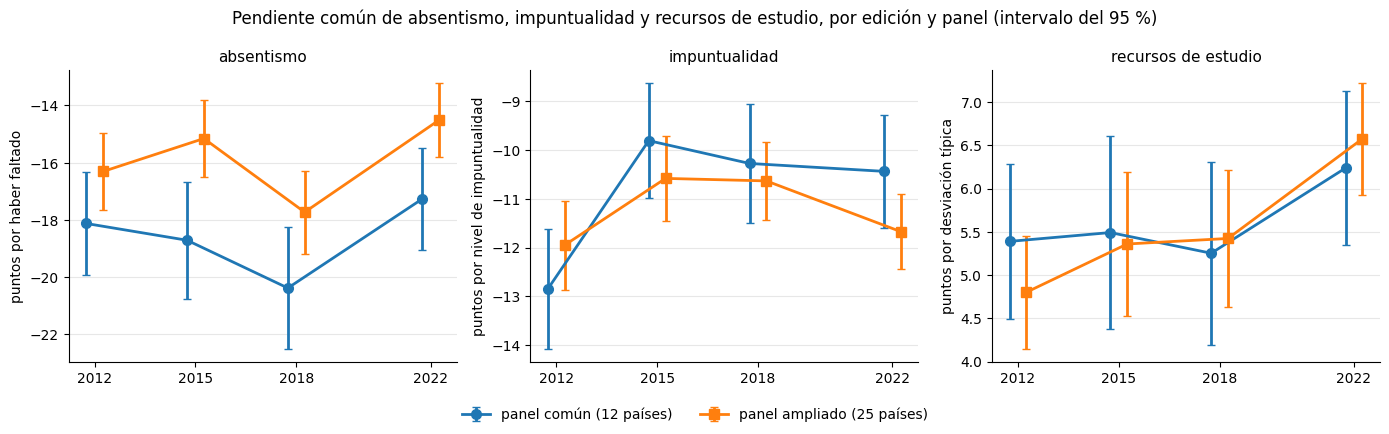

In [9]:
# Panel de 25 países con las cuatro ediciones (en 2018 el índice queda vacío)
tabla_cuatro_ediciones = marcar_universo(tabla_por_alumno(RUTA_RAW_BASE, RUTA_INTERMEDIOS, panel='ampliado', ediciones=EDICIONES))
poco_cuatro_ediciones = perfiles_poco_representativos(tabla_cuatro_ediciones)
excluidos = set(tabla_cuatro_ediciones.loc[tabla_cuatro_ediciones['perfil_excluido'], 'perfil'])
# Alumnos con absentismo, impuntualidad y recursos de estudio
con_asistencia = ~tabla_cuatro_ediciones['perfil_excluido'] & tabla_cuatro_ediciones[['recursos_estudio', 'SKIPPING', 'TARDYSD']].notna().all(axis=1)
print(f"{tabla_cuatro_ediciones['CNT'].nunique()} países; perfiles excluidos:", sorted(excluidos))
print('Perfiles-edición poco representativos (de los que entran):', [indice for indice, valor in poco_cuatro_ediciones.items() if valor and indice[0] not in excluidos])
print('% de alumnos con perfil que tienen absentismo, impuntualidad y recursos de estudio, por edición:',
      (100 * con_asistencia.groupby(tabla_cuatro_ediciones['year']).mean()).round(1).to_dict())

# Dos especificaciones: solo asistencia (cuatro ediciones) y los tres componentes (sin 2018)
asistencia_ampliado = 'sin deberes, panel ampliado con 2018'
especificaciones_ampliado = {asistencia_ampliado: (con_asistencia, ['SKIPPING', 'TARDYSD', 'recursos_estudio']),
                             'componentes del índice, panel ampliado': (con_asistencia & tabla_cuatro_ediciones['deberes_en_u'].notna(),
                                                                         ['deberes_en_u', 'SKIPPING', 'TARDYSD', 'recursos_estudio'])}
# Cada una con su propia escala
comunes_ampliado, perfiles_ampliado = {}, {}
for nombre, (en_modelo, de_interes) in especificaciones_ampliado.items():
    tabla_especificacion = tabla_cuatro_ediciones.assign(en_modelo=en_modelo)
    matriz_especificacion = matriz_regresion(tabla_especificacion, parametros_escala(tabla_especificacion))
    resumen, comunes_ampliado[nombre], perfiles_ampliado[nombre] = estimar_especificacion(nombre, matriz_especificacion, poco_cuatro_ediciones,
                                                                                            de_interes=de_interes)
    resumenes.append(resumen)
    display(Markdown(f'**{nombre}**: alumnos por edición {matriz_especificacion.groupby("year").size().to_dict()}; pendiente común por edición (error típico)'))
    display(pendientes_comunes(comunes_ampliado[nombre], de_interes))
    display(resumen.drop(columns=['especificacion', 'alumnos']).round(3).set_index('variable'))

perfiles_asistencia = orden_perfiles(tabla_cuatro_ediciones.loc[con_asistencia, 'perfil'].unique())
display(Markdown(f'**{asistencia_ampliado}**: pendiente de los recursos de estudio por perfil y edición (error típico)'))
display(con_error_perfil(perfiles_ampliado[asistencia_ampliado], [f'recursos_estudio:{perfil}' for perfil in perfiles_asistencia]).reindex(perfiles_asistencia)
        .assign(poco_representativo=[', '.join(str(edicion) for edicion in EDICIONES if poco_cuatro_ediciones[(perfil, edicion)]) for perfil in perfiles_asistencia]))

# Países frente a medida: el cambio de los recursos de estudio en las cinco especificaciones
separacion = {'modelo de partida': ('común', 'índice'), 'sin deberes, muestra ampliada': ('común', 'asistencia'),
              'panel ampliado (25 países)': ('ampliado', 'índice'), 'componentes del índice, panel ampliado': ('ampliado', 'componentes'),
              asistencia_ampliado: ('ampliado', 'asistencia')}
comparacion = pd.concat(resumenes, ignore_index=True)
comparacion = comparacion[comparacion['especificacion'].isin(separacion) & (comparacion['variable'] == 'recursos_estudio')].copy()
comparacion[['panel', 'compromiso medido con']] = comparacion['especificacion'].map(separacion).tolist()
display(Markdown(f'**Recursos de estudio: cambio de {INICIO} a {FINAL} según el panel y la medida del compromiso**'))
display(comparacion.set_index(['panel', 'compromiso medido con'])[['cambio', 'p_cambio', f'p_igualdad_perfiles_{FINAL}', 'p_igualdad_cambio',
                                                                    f'cambio_{PERFIL_REVISADO}', f'p_{PERFIL_REVISADO}']].round(3))

# Pendiente común por edición con la asistencia, en los dos paneles
# Figura: pendiente común con la asistencia en los dos paneles
lineas = {'panel común (12 países)': (comunes_compromiso['sin deberes, muestra ampliada'], '#1f77b4', 'o'),
          'panel ampliado (25 países)': (comunes_ampliado[asistencia_ampliado], '#ff7f0e', 's')}
unidades = {'SKIPPING': 'puntos por haber faltado', 'TARDYSD': 'puntos por nivel de impuntualidad', 'recursos_estudio': 'puntos por desviación típica'}
fig, ejes = plt.subplots(1, 3, figsize=(14, 4.3))
for eje, variable in zip(ejes, unidades):
    for desplazamiento, (etiqueta, (comun, color, marcador)) in zip((-0.25, 0.25), lineas.items()):
        filas = comun.xs(variable, level='termino')
        eje.errorbar(filas.index + desplazamiento, filas['coeficiente'], yerr=1.96 * filas['error_tipico'], color=color, marker=marcador,
                     markersize=7, linewidth=2, capsize=3, label=etiqueta)
    eje.set_title(NOMBRES[variable], fontsize=11)
    eje.set_xticks(EDICIONES)
    eje.set_ylabel(unidades[variable])
    eje.grid(axis='y', alpha=0.3)
    eje.spines[['top', 'right']].set_visible(False)
fig.legend(*ejes[0].get_legend_handles_labels(), loc='lower center', ncol=2, frameon=False)
fig.suptitle('Pendiente común de absentismo, impuntualidad y recursos de estudio, por edición y panel (intervalo del 95 %)', fontsize=12)
plt.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(f'{RUTA_REPORTS}/03_robustez_asistencia_panel_ampliado.png', dpi=300, bbox_inches='tight')
plt.show()

**Qué se ve.**

* **Con solo la asistencia, el panel ampliado recupera 2018.** El 80,8 % de los alumnos con perfil tiene absentismo, impuntualidad y recursos de estudio en 2018 (entre el 84,7 % y el 97,3 % en las demás ediciones). Los perfiles excluidos y poco representativos son los mismos que en la sección 6.
* **La subida de los recursos en el panel ampliado no depende de cómo se mida el compromiso.**
  * En el panel ampliado, el cambio de 2012 a 2022 es de 1,60 puntos con el índice, 1,70 con sus componentes y 1,77 con la asistencia (p de 0,002 o menos en los tres).
  * En el panel común es de 0,46 con el índice y 0,85 con la asistencia (p = 0,514 y 0,187).
  * La diferencia entre paneles viene, por tanto, de los países, no de la medida del compromiso ni de que falte 2018.
* **En los dos paneles la pendiente de los recursos sube sobre todo en 2022.**
  * Panel ampliado: 4,80, 5,36, 5,42 y 6,57 puntos por desviación típica en las cuatro ediciones.
  * Panel común con la asistencia (sección 2): 5,39, 5,49, 5,25 y 6,24.
  * El panel ampliado parte de más abajo en 2012 y tiene errores más pequeños (0,33 frente a 0,45 en 2022), y por eso su cambio sí se distingue de cero. Las pendientes están en desviaciones típicas de cada panel, así que el nivel solo se compara de forma aproximada.
* **Las pendientes de los recursos difieren entre perfiles en 2022 con cualquier medida del compromiso** (p < 0,001 en el panel ampliado), y su cambio también (p entre 0,018 y 0,022).
  * Con la asistencia, el privado urbano grande pasa de 7,1 en 2012 y 4,2 en 2018 a 17,7 en 2022 (cambio de 10,62, p = 0,003). Su subida es de 2022, no una tendencia.
  * En 2022 el privado urbano mediano está en 14,1; los públicos, entre 3,9 y 7,9; el privado urbano pequeño, en −0,1.
* **La subida del índice de compromiso en el panel ampliado también viene de los deberes.** Estar en el tercil central pasa de −1,53 puntos en 2012 a 5,73 en 2022 (+7,26, p < 0,001). El absentismo cambia +1,75 (p = 0,107) y la impuntualidad −0,08 (p = 0,910).
* **La asistencia pesa lo mismo de 2012 a 2022, también con las cuatro ediciones.**
  * Faltar resta 16,31 puntos en 2012, 17,74 en 2018 y 14,51 en 2022 (cambio +1,80, p = 0,061).
  * Cada nivel de impuntualidad resta 11,95 en 2012 y 11,67 en 2022 (p = 0,650).
* **Un resultado nuevo: en el privado urbano grande, faltar penaliza mucho menos en 2022.** Pasa de −26,21 a −8,33 puntos (+17,88, p = 0,003), y el cambio difiere entre perfiles (p = 0,010). En el panel común va en la misma dirección (de −36,72 a −19,56, p = 0,028). Es el mismo perfil y la misma edición que la subida de los recursos, pero depende de Corea, que casi sale del perfil en 2022 (apartado siguiente).

### 8.1 Absentismo en el privado urbano grande, sin cada país

La subida de los recursos de estudio en el privado urbano grande depende de Australia (sección 7). Aquí se comprueba si el otro resultado nuevo de este perfil, que faltar penaliza menos en 2022, depende también de un país. Se repite el modelo con la asistencia quitando cada país, en el panel ampliado (cuatro ediciones) y en el común (la «muestra ampliada» de la sección 2), con la misma escala y los mismos perfiles poco representativos que en la sección 7.

In [10]:
# La muestra con asistencia de cada panel; la escala no cambia al quitar un país
matriz_asistencia_ampliado = matriz_regresion(tabla_cuatro_ediciones.assign(en_modelo=con_asistencia),
                                              parametros_escala(tabla_cuatro_ediciones.assign(en_modelo=con_asistencia)))
paneles_asistencia = {'ampliado': (tabla_cuatro_ediciones, matriz_asistencia_ampliado), 'común': (tabla, matriz_sin_deberes)}
for panel, (_, matriz_panel) in paneles_asistencia.items():
    centros = matriz_panel[matriz_panel['perfil'] == PERFIL_REVISADO].groupby(['CNT', 'year'])['centro'].nunique().unstack(fill_value=0)
    display(Markdown(f'**Panel {panel}: centros de {PERFIL_REVISADO} por país y edición, en la muestra con asistencia**'))
    display(centros.sort_values(INICIO, ascending=False))

# El modelo con la asistencia sin cada país; se guarda el absentismo del privado urbano grande
filas = []
for panel, (tabla_panel, matriz_panel) in paneles_asistencia.items():
    for pais in ['ninguno'] + sorted(matriz_panel['CNT'].unique()):
        sin_el_pais = matriz_panel if pais == 'ninguno' else matriz_panel[matriz_panel['CNT'] != pais]
        tabla_sin_el_pais = tabla_panel if pais == 'ninguno' else tabla_panel[tabla_panel['CNT'] != pais]
        resumen, _, _ = estimar_especificacion(f'asistencia, panel {panel} sin {pais}', sin_el_pais, perfiles_poco_representativos(tabla_sin_el_pais),
                                               de_interes=['SKIPPING', 'TARDYSD', 'recursos_estudio'])
        fila = resumen.set_index('variable').loc['SKIPPING']
        filas.append({'panel': panel, 'pais_quitado': pais, f'absentismo_{INICIO}': fila[f'{PERFIL_REVISADO}_{INICIO}'],
                      f'absentismo_{FINAL}': fila[f'{PERFIL_REVISADO}_{FINAL}'], 'cambio': fila[f'cambio_{PERFIL_REVISADO}'],
                      'p_cambio': fila[f'p_{PERFIL_REVISADO}'], 'p_igualdad_cambio': fila['p_igualdad_cambio'],
                      'poco_representativo': fila[f'{PERFIL_REVISADO}_poco_representativo']})
absentismo_sin_pais = pd.DataFrame(filas).set_index(['panel', 'pais_quitado'])
display(Markdown(f'**Pendiente del absentismo en {PERFIL_REVISADO} ({INICIO} y {FINAL}) y su cambio, sin cada país**'))
display(absentismo_sin_pais.round(3))
for panel in paneles_asistencia:
    de_panel = absentismo_sin_pais.loc[panel]
    print(f'Panel {panel}: sin qué país el cambio deja de ser distinto de cero al 5 %:', sorted(de_panel.index[de_panel['p_cambio'] >= 0.05]))

**Panel ampliado: centros de PRI_URB_MACRO por país y edición, en la muestra con asistencia**

year,2012,2015,2018,2022
CNT,,,,
AUS,63,65,64,80
CHL,27,24,31,26
JPN,27,31,23,29
KOR,21,14,5,4
ESP,18,6,27,21
MEX,11,3,4,1
PRT,6,3,6,8
GBR,4,4,5,9
USA,3,0,2,1


**Panel común: centros de PRI_URB_MACRO por país y edición, en la muestra con asistencia**

year,2012,2015,2018,2022
CNT,,,,
AUS,63,65,64,80
KOR,21,14,5,4
ESP,18,6,27,21
GBR,4,4,5,9
GRC,1,0,0,0
DNK,0,0,1,0


**Pendiente del absentismo en PRI_URB_MACRO (2012 y 2022) y su cambio, sin cada país**

absentismo_2012  absentismo_2022  cambio  p_cambio  p_igualdad_cambio  poco_representativo
panel    pais_quitado                                                                                            
ampliado ninguno               -26.206           -8.330  17.876     0.003              0.010                False
         AUS                   -34.811          -10.818  23.993     0.001              0.006                False
         CHE                   -26.034           -8.440  17.594     0.003              0.010                False
         CHL                   -29.950           -9.542  20.408     0.002              0.016                False
         CZE                   -26.026           -8.200  17.825     0.003              0.019                False
         DEU                   -26.054           -8.270  17.783     0.003              0.010                False
         DNK                   -26.436           -8.309  18.126     0.002              0.006                False
         ESP                   -23.923           -6.232  17.692     0.006              0.023                False
         EST                   -26.224           -8.274  17.949     0.003              0.005                False
         FIN                   -26.311           -8.255  18.056     0.002              0.006                False
         FRA                   -25.922           -7.930  17.992     0.003              0.005                False
         GBR                   -26.281           -7.953  18.328     0.003              0.014                False
         GRC                   -26.698           -8.365  18.333     0.002              0.019                False
         HUN                   -25.822           -8.191  17.631     0.003              0.011                False
         ISL                   -26.256           -8.295  17.961     0.003              0.018                False
         ITA                   -26.116           -8.396  17.720     0.003              0.002                False
         JPN                   -29.161          -11.862  17.299     0.004              0.006                False
         KOR                   -14.318           -6.576   7.743     0.176              0.073                False
         MEX                   -26.609           -8.227  18.383     0.003              0.003                False
         NLD                   -26.152           -8.965  17.187     0.004              0.030                False
         POL                   -26.236           -8.456  17.780     0.003              0.015                False
         PRT                   -26.508           -8.632  17.876     0.005              0.021                False
         SVK                   -25.858           -8.265  17.594     0.003              0.009                False
         SVN                   -25.828           -8.421  17.407     0.003              0.008                False
         TUR                   -25.321           -8.451  16.870     0.005              0.055                False
         USA                   -27.075           -8.763  18.311     0.003              0.009                False
común    ninguno               -36.720          -19.558  17.162     0.028              0.140                False
         AUS                   -59.802          -29.892  29.910     0.012              0.072                False
         DNK                   -37.321          -19.529  17.793     0.023              0.083                False
         ESP                   -29.981          -20.663   9.317     0.274              0.483                False
         GBR                   -37.189          -18.964  18.225     0.027              0.067                False
         GRC                   -37.777          -19.559  18.218     0.020              0.127                False
         HUN                   -36.193          -19.449  16.743     0.031              0.155                False
         ISL                   -3

Panel ampliado: sin qué país el cambio deja de ser distinto de cero al 5 %: ['KOR']
Panel común: sin qué país el cambio deja de ser distinto de cero al 5 %: ['ESP', 'KOR']


**Qué se ve.**

* **El resultado depende de Corea, no de Australia.**
  * Sin Corea, el cambio del absentismo en el privado urbano grande baja de 17,88 a 7,74 puntos en el panel ampliado (p = 0,176), y de 17,16 a 5,49 en el común (p = 0,421).
  * Sin Australia, el cambio es mayor (23,99 y 29,91, p = 0,001 y 0,012).
  * En el panel común también deja de distinguirse de cero sin España (9,32, p = 0,274). En el ampliado, España no lo mueve (17,69, p = 0,006), y ningún otro país lo cambia.
* **Corea casi desaparece de este perfil entre 2012 y 2022.** Aporta 21 centros en 2012, 14 en 2015, 5 en 2018 y 4 en 2022. Sin Corea, faltar resta 14,32 puntos en 2012 en el panel ampliado, en lugar de 26,21. La fuerte penalización de 2012 era, por tanto, la de los privados urbanos grandes coreanos.
* **No es un cambio de la relación dentro de los centros, sino de qué países forman el perfil.** Como el modelo tiene efecto fijo de país pero una sola pendiente por perfil, la pendiente del perfil es una media de los países que lo componen; si Corea sale del perfil, la media cambia aunque nada cambie dentro de cada país. Este resultado no se usa como hallazgo.

## 9. La no respuesta

El modelo solo usa los alumnos que tienen el índice de compromiso y los recursos de estudio. `01_EDA_variables_modelo` muestra que los que no los tienen sacan menos nota, pero es una comparación bruta: podría deberse solo a que tienen un origen social más bajo.

Para separarlo, se estima una regresión sobre todos los alumnos de los perfiles no excluidos, tengan o no las variables de interés. La nota se explica con dos indicadores, `sin_compromiso` y `sin_recursos` (1 = sin dato), primero solo con el efecto fijo de país y de perfil y después con los controles del modelo. El coeficiente de cada indicador es la diferencia de nota entre los alumnos sin dato y los que lo tienen, en el mismo país y perfil y, en la segunda, con el mismo origen social y centro. Después se repite con un indicador por perfil y se contrasta si la diferencia es igual en todos.

In [11]:
# Todos los alumnos de perfiles no excluidos, tengan o no las variables de interés, con un indicador de cada hueco
con_y_sin_dato = ~tabla['perfil_excluido']
matriz_no_respuesta = matriz_regresion(tabla.assign(en_modelo=con_y_sin_dato), parametros)
INDICADORES_HUECO = {'sin_compromiso': 'Indice_Compromiso_Competencia', 'sin_recursos': 'recursos_estudio'}
for indicador, variable in INDICADORES_HUECO.items():
    matriz_no_respuesta[indicador] = matriz_no_respuesta[variable].isna().astype(float)
huecos = list(INDICADORES_HUECO)

porcentaje_huecos = matriz_no_respuesta.groupby('year')[huecos].mean().mul(100).round(1)
porcentaje_huecos.insert(0, 'alumnos', matriz_no_respuesta.groupby('year').size())
display(Markdown('**Alumnos de perfiles no excluidos y % sin cada variable de interés**'))
display(porcentaje_huecos)

# Diferencia de nota de los alumnos sin dato, sin controles (solo país y perfil) y con los controles del modelo
for titulo, controles in {'solo efecto fijo de país y perfil': [], 'con los controles del modelo': CONTROLES}.items():
    comun_huecos, _ = estimar_por_edicion(matriz_no_respuesta, False, controles=controles, de_interes=huecos)
    display(Markdown(f'**Puntos de matemáticas de los alumnos sin dato frente a los que tienen dato, {titulo} (error típico)**'))
    display(coeficientes_con_error(comun_huecos, huecos))

# Por perfil, con controles: contraste de que la diferencia es igual en los perfiles con centros suficientes
perfil_huecos, covarianzas_huecos = estimar_por_edicion(matriz_no_respuesta, True, controles=CONTROLES, de_interes=huecos)
display(Markdown('**Puntos de los alumnos sin compromiso por perfil, con controles (error típico)**'))
display(con_error_perfil(perfil_huecos, [f'sin_compromiso:{perfil}' for perfil in ORDEN_PERFILES]).loc[ORDEN_PERFILES])
contrastes_huecos = {}
for edicion in EDICIONES:
    fiables = [perfil for perfil in ORDEN_PERFILES if not poco_representativo[(perfil, edicion)]]
    for indicador in huecos:
        _, _, contrastes_huecos[(indicador, edicion)] = contraste_igualdad(perfil_huecos.xs(edicion, level='year')['coeficiente'], covarianzas_huecos[edicion],
                                                                           [f'{indicador}:{perfil}' for perfil in fiables])
display(Markdown('**Valor p del contraste de que la diferencia es igual en todos los perfiles (sin los poco representativos)**'))
display(pd.Series(contrastes_huecos).unstack().round(4))


**Alumnos de perfiles no excluidos y % sin cada variable de interés**

,alumnos,sin_compromiso,sin_recursos
year,,,
2012,115260,35.5,1.6
2015,77768,11.0,2.4
2018,109415,35.9,2.9
2022,104612,9.4,13.3


**Puntos de matemáticas de los alumnos sin dato frente a los que tienen dato, solo efecto fijo de país y perfil (error típico)**

year,2012,2015,2018,2022
termino,,,,
sin_compromiso,-5.2 (0.9),-42.3 (2.0),-25.7 (1.2),-48.2 (2.0)
sin_recursos,-90.9 (3.9),-46.0 (4.8),-36.7 (4.4),-33.9 (1.5)


**Puntos de matemáticas de los alumnos sin dato frente a los que tienen dato, con los controles del modelo (error típico)**

year,2012,2015,2018,2022
termino,,,,
sin_compromiso,-2.9 (0.8),-27.7 (1.7),-17.6 (1.0),-41.4 (1.9)
sin_recursos,-33.7 (4.1),-25.3 (5.4),-18.1 (5.7),-24.1 (1.3)


**Puntos de los alumnos sin compromiso por perfil, con controles (error típico)**

year,2012,2015,2018,2022
PUB_RUR_MACRO,-0.5 (4.7),-29.3 (6.8),-15.8 (4.9),-42.0 (5.9)
PUB_RUR_MED,-2.5 (3.0),-30.0 (5.8),-17.6 (3.3),-47.7 (5.0)
PUB_RUR_PEQ,-5.1 (2.1),-20.8 (4.5),-12.9 (2.6),-43.7 (4.7)
PUB_URB_MACRO,-3.0 (1.5),-33.7 (3.6),-21.8 (2.5),-44.5 (3.6)
PUB_URB_MED,-3.4 (1.7),-28.0 (3.0),-17.4 (2.1),-43.9 (3.4)
PUB_URB_PEQ,-1.8 (1.9),-23.3 (3.3),-15.1 (2.4),-41.6 (3.9)
CON_RUR_MACRO,-14.3 (7.5),-45.9 (20.6),-26.2 (10.5),-41.1 (14.2)
CON_RUR_MED,3.6 (9.2),-20.0 (14.5),-28.6 (9.4),-11.1 (11.2)
CON_RUR_PEQ,1.6 (6.2),-36.3 (9.8),-20.1 (9.5),-22.9 (13.8)
CON_URB_MACRO,-1.4 (2.4),-38.1 (7.1),-25.0 (3.8),-26.9 (5.2)


**Valor p del contraste de que la diferencia es igual en todos los perfiles (sin los poco representativos)**

,2012,2015,2018,2022
sin_compromiso,0.7874,0.3009,0.0447,0.0072
sin_recursos,0.0003,0.6078,0.0000,0.5088


**Qué se ve.**

* **Los alumnos sin dato sacan menos nota también con el mismo origen social.**
  * Con los controles, los que no tienen el compromiso sacan 27,7 puntos menos en 2015, 17,6 en 2018 y 41,4 en 2022.
  * Los que no tienen los recursos sacan entre 18,1 y 33,7 puntos menos.
  * Los controles reducen la diferencia (en los recursos de 2012, de −90,9 a −33,7 puntos), pero no la eliminan: la no respuesta no es solo cuestión de origen social.
* **La excepción es el compromiso de 2012.** Falta al 35,5 % de los alumnos por la rotación del cuestionario y casi no se asocia a la nota (−2,9 puntos con controles). En 2018 también falta a muchos (35,9 %), pero la diferencia es mayor (−17,6).
* **La selección crece de 2012 a 2022.** En 2022 el compromiso falta a menos alumnos (9,4 %), pero los que no lo tienen se alejan mucho más (−41,4 puntos frente a −2,9). La muestra del modelo de 2022 está más seleccionada que la de 2012, así que el cambio de la pendiente del compromiso compara muestras que no se seleccionan igual.
* **Por perfil, la diferencia del compromiso es parecida hasta 2018** (p = 0,787 en 2012, 0,301 en 2015 y 0,045 en 2018, al borde). En 2022 difiere (p = 0,007): en los públicos está entre −41,6 y −47,7 puntos, y en varios concertados es menor, con errores grandes (−26,9 en el concertado urbano grande, −11,1 en el concertado rural mediano).
* **En los recursos, los perfiles difieren en 2012 y 2018** (p < 0,001), pero en esas ediciones solo falta al 1,6 % y al 2,9 % de los alumnos, así que cada perfil tiene muy pocos alumnos sin dato.
* **Qué implica.** Las pendientes del modelo valen para los alumnos que contestan, que sacan más nota que los demás incluso con el mismo origen social. Esta sección no estima pendientes, así que no entra en el resumen ni en `resultados_robustez.parquet`.

## 10. Resumen

El gráfico junta, para las especificaciones que usan el índice de compromiso y los recursos de estudio en escala continua, los tres resultados de `03_regresion_por_edicion`: el cambio de 2012 a 2022 de la pendiente común de cada variable y el cambio de la pendiente de los recursos en el privado urbano grande. La línea discontinua es el modelo de partida. Las especificaciones de las secciones 2, 3 y 8 miden las variables de otra forma y se leen en sus tablas; la sección 9 no estima pendientes.

Todas las filas, también las de la sección 7 (con el panel y el país quitado), se guardan en `data/processed/resultados_robustez.parquet`, para que el agente pueda explicar hasta dónde aguantan los resultados.

,,cambio,p_cambio,p_igualdad_perfiles_2022,p_igualdad_cambio,cambio_PRI_URB_MACRO,p_PRI_URB_MACRO
variable,especificacion,,,,,,
compromiso,modelo de partida,1.481,0.029,0.686,0.848,-1.634,0.657
recursos de estudio,modelo de partida,0.458,0.514,0.003,0.032,14.256,0.001
compromiso,ESCS del centro en lugar de composición social,1.255,0.062,0.449,0.742,-2.149,0.543
recursos de estudio,ESCS del centro en lugar de composición social,0.733,0.295,0.001,0.040,14.703,0.001
compromiso,con la escasez del centro,1.470,0.030,0.708,0.846,-2.019,0.584
recursos de estudio,con la escasez del centro,0.463,0.510,0.004,0.031,14.338,0.001
compromiso,panel ampliado (25 países),2.383,0.000,0.034,0.150,-2.108,0.467
recursos de estudio,panel ampliado (25 países),1.597,0.002,0.000,0.019,9.236,0.012
compromiso,sin AUS,1.348,0.062,0.691,0.884,2.177,0.697


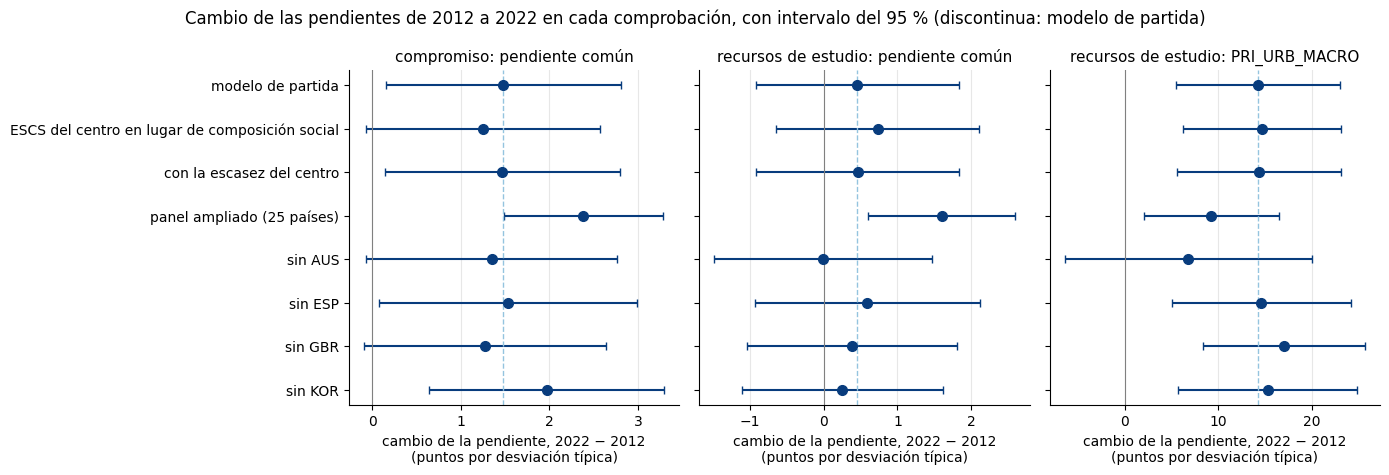

110 filas (51 especificaciones) en ../../data/processed\resultados_robustez.parquet


In [12]:
# Especificaciones comparables con el modelo de partida (mismas variables de interés)
robustez = pd.concat(resumenes, ignore_index=True)
comparables = robustez[robustez['variable'].isin(DE_INTERES) & ~robustez['especificacion'].str.startswith(('componentes', 'sin deberes', 'recursos por tramos'))]
orden = sorted(dict.fromkeys(comparables['especificacion']), key=lambda nombre: (nombre != 'modelo de partida', nombre.startswith('sin ')))   # los modelos sin un país, al final
comparables = comparables.set_index('especificacion').loc[orden].reset_index()
columnas = ['cambio', 'p_cambio', f'p_igualdad_perfiles_{FINAL}', 'p_igualdad_cambio', f'cambio_{PERFIL_REVISADO}', f'p_{PERFIL_REVISADO}']
display(comparables.assign(variable=comparables['variable'].map(NOMBRES)).set_index(['variable', 'especificacion'])[columnas].round(3))

# Figura: cambio de las pendientes en cada comprobación
paneles = [('Indice_Compromiso_Competencia', 'cambio', 'error_cambio', 'compromiso: pendiente común'),
           ('recursos_estudio', 'cambio', 'error_cambio', 'recursos de estudio: pendiente común'),
           ('recursos_estudio', f'cambio_{PERFIL_REVISADO}', f'error_{PERFIL_REVISADO}', f'recursos de estudio: {PERFIL_REVISADO}')]
fig, ejes = plt.subplots(1, 3, figsize=(14, 4.8), sharey=True)
for eje, (variable, columna, columna_error, titulo) in zip(ejes, paneles):
    filas = comparables[comparables['variable'] == variable].set_index('especificacion').loc[orden]
    posicion = np.arange(len(orden))
    eje.errorbar(filas[columna], posicion, xerr=1.96 * filas[columna_error], fmt='o', color=COLORES_EDICION[2022], markersize=7, elinewidth=1.5, capsize=3)
    eje.axvline(0, color='grey', linewidth=0.8)
    eje.axvline(filas.loc['modelo de partida', columna], color=COLORES_EDICION[2012], linestyle='--', linewidth=1)
    eje.set_title(titulo, fontsize=11)
    eje.set_xlabel(f'cambio de la pendiente, {FINAL} − {INICIO}\n(puntos por desviación típica)')
    eje.grid(axis='x', alpha=0.3)
    eje.spines[['top', 'right']].set_visible(False)
ejes[0].set_yticks(np.arange(len(orden)), orden)
ejes[0].invert_yaxis()
fig.suptitle(f'Cambio de las pendientes de {INICIO} a {FINAL} en cada comprobación, con intervalo del 95 % (discontinua: modelo de partida)', fontsize=12)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/03_robustez_resumen.png', dpi=300, bbox_inches='tight')
plt.show()

# Todas las especificaciones, incluidas las de sin cada país, en un parquet
ruta = os.path.join(RUTA_PROCESADOS, 'resultados_robustez.parquet')
robustez = pd.concat([robustez, sin_pais], ignore_index=True)
robustez.to_parquet(ruta, index=False)
print(f'{len(robustez)} filas ({robustez["especificacion"].nunique()} especificaciones) en {ruta}')

**Qué se ve.**

* **El cambio del compromiso es siempre positivo**, de 1,26 a 2,38 puntos. Su intervalo roza el cero en tres de las ocho comprobaciones (`ESCS` del centro, sin Australia y sin Reino Unido).
* **El de los recursos de estudio está siempre cerca de cero en el panel común**, entre −0,004 y 0,73. Solo se distingue de cero en el panel ampliado (1,60).
* **El privado urbano grande aguanta todas las comprobaciones menos una.** Aguanta el cambio de controles, el panel ampliado y quitar España, Reino Unido o Corea. Se queda sin significación al quitar Australia (6,77, p = 0,316).

## Hallazgos

* **La relación del compromiso con la nota se mantiene o se refuerza algo de 2012 a 2022, igual en todos los perfiles.**
  * El signo del cambio aguanta en todas las comprobaciones (de +1,26 a +2,38 puntos por desviación típica), pero su significación es justa en el panel común (p entre 0,004 y 0,068).
  * Quitando los países de uno en uno (sección 7), el cambio sigue entre +1,05 y +2,19, pero deja de ser significativo sin alguno de seis países (Australia, Reino Unido, Hungría, Italia, Eslovaquia o Eslovenia). No se debe a un país: es un cambio pequeño medido con poca precisión. En el panel ampliado es significativo se quite el país que se quite.
  * Por componentes, la subida viene de los deberes, el componente que peor se compara entre ediciones, en los dos paneles (sección 8).
  * El absentismo pesa lo mismo (unos 17-18 puntos menos por faltar) y la impuntualidad algo menos.
  * La única excepción aparente, que faltar penaliza menos en 2022 en el privado urbano grande, desaparece sin Corea, que pasa de 21 centros de ese perfil en 2012 a 4 en 2022 (sección 8).
  * Conviene presentarlo como «estable o ligeramente más fuerte», no como un cambio claro.
* **La relación de los recursos de estudio es estable en el panel común**, con cualquier control y con tramos en lugar de la escala continua. En el panel ampliado de 25 países sube 1,60 puntos (p = 0,002). La conclusión depende, por tanto, del grupo de países, no de la medida del compromiso: midiéndolo solo con la asistencia, con las cuatro ediciones, sube 1,77 puntos en el panel ampliado (p < 0,001) y 0,85 en el común (p = 0,187) (sección 8).
* **El efecto techo existe, pero no explica los resultados.**
  * Más de la mitad de los alumnos tiene los seis recursos.
  * La relación se aplana cerca del techo.
  * Con tramos, las conclusiones no cambian.
* **En el panel común, la diferencia entre perfiles de 2022 es la de los privados urbanos grandes australianos.**
  * Resiste los controles alternativos, los tramos y quitar cualquier otro país.
  * Desaparece al quitar Australia, que aporta la mayoría de sus centros.
  * Quitando los países de uno en uno (sección 7), Australia es el único que cambia esa conclusión.
  * El cambio dentro de Australia se analiza en `03_australia_privados_grandes`.
* **En el panel ampliado de 25 países, las pendientes de los recursos difieren entre perfiles en 2022 sin depender de ningún país.**
  * Los privados urbanos grandes y medianos (entre 14 y 17 puntos por desviación típica) quedan por encima de los públicos (entre 4 y 7), también sin Australia.
  * No se debe a la medida del compromiso ni a que falte 2018: con la asistencia y las cuatro ediciones, la diferencia se mantiene (p < 0,001), y el privado urbano grande pasa de 4,2 en 2018 a 17,7 en 2022 (sección 8).
* **El compromiso es igual en todos los perfiles en los dos paneles**, salvo una diferencia frágil en 2022 en el panel ampliado, que desaparece al quitar alguno de seis países.
* **La no respuesta no se explica solo por el origen social (sección 9).**
  * Con los controles, el país y el perfil, los alumnos sin compromiso sacan 41,4 puntos menos en 2022, y los alumnos sin recursos, entre 18,1 y 33,7 menos según la edición.
  * Solo el compromiso de 2012, que falta por la rotación del cuestionario, falta casi al azar (−2,9 puntos).
  * Los resultados valen para los alumnos que contestan, y en 2022 esa selección es más fuerte que en 2012.
* **Respuesta a la pregunta del TFM tras las comprobaciones.**
  * El compromiso se asocia al doble de nota que los recursos de estudio, con una relación igual en todos los perfiles.
  * La relación de los recursos de estudio no cambia en el panel común, salvo en Australia. En el panel ampliado se refuerza y, en 2022, más en los privados urbanos grandes y medianos.
  * Con la asistencia, que existe en los 25 países y las cuatro ediciones, la diferencia entre paneles se mantiene: es de los países, no de la medida. Elegir el panel es elegir a qué países se aplica la conclusión.

**Siguiente notebook**: `03_australia_privados_grandes`, que analiza el salto del privado urbano grande en Australia. Después, `03_xgboost_shap` comprueba con otro modelo la forma de las relaciones y las diferencias entre perfiles.